# R7 · Limites et dérivation — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookMaths/blob/main/chapitres/r7_limites_derivation/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wbm.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | R7.1 à R7.11, R7.15 | Les exercices papier (vérification) | ✏️ 🔗 | | |
| A | R7.17 | Le taux d'accroissement · `difference_quotient` | 🔨 | ★ | 15 |
|  | R7.18 | La tangente à partir de f et de sa dérivée · `tangent_line` | 🔨 | ★★ | 20 |
|  | R7.19 | Trouver un zéro par dichotomie · `bisection` | 🔨 | ★★ | 25 |
| B | R7.20 | Vérifier ses dérivées avec `sympy.diff` | 📦 | ★ | 15 |
|  | R7.21 | Prédire : le taux d'accroissement a-t-il toujours une limite quand h tend vers 0 ? | 🔮 | ★★ | 15 |
|  | R7.22 | Zoomer sur une courbe jusqu'à voir une droite | 🔬 | ★★ | 20 |
|  | R7.23 | Tracer f, f′ et des tangentes | 🎨 | ★★ | 20 |
| C | R7.24 | Chasse à l'erreur : quatre dérivées fausses | 🐛 | ★★ | 20 |
|  | R7.25 | Tester une dérivée avec pytest et SymPy | 🛠️ | ★ | 15 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (a few seconds per cell); False = bigger experiments
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookMaths.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookMaths")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WBM_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wbm").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wbm").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier de workbookMaths.")

os.environ["WBM_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wbm  # noqa: E402

cfg = wbm.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mymath = wbm.load_mymath("ref")  # reference implementation

🧪 workbookMaths : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | scipy 1.16.3 | sympy 1.14.0 | matplotlib 3.10.0 | pandas 2.2.3 | scikit-learn 1.6.1
   Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Vérifier tes calculs papier (partie 0) : limites et asymptotes, taux d'accroissement, tangentes, dérivées (usuelles, produits, quotients, composées, une lettre à la fois), variations et optimisation.
- Écrire les trois fonctions de `mymath/deriv.py` et les tester.
- Dériver avec SymPy, prévoir quand un taux d'accroissement a une limite, zoomer sur une courbe, tracer f et f′, chasser des dérivées fausses et écrire un test.

**Rappel express.** $f'(a) = \lim_{h \to 0} \frac{f(a + h) - f(a)}{h}$ ; tangente : $y = f(a) + f'(a)(x - a)$. $(x^n)' = n x^{n-1}$, $(e^x)' = e^x$, $(\ln x)' = \frac{1}{x}$, $(\sqrt{x})' = \frac{1}{2\sqrt{x}}$. $(uv)' = u'v + uv'$, $\left(\frac{u}{v}\right)' = \frac{u'v - uv'}{v^2}$, $\big(g(u)\big)' = g'(u) \times u'$. $f' > 0$ : $f$ croît ; un extremum intérieur annule $f'$.

## Partie 0 · Vérifier tes exercices papier (✏️ R7.1 à R7.11, 🔗 R7.15)

Fais d'abord les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse ici : **la valeur** que tu as trouvée, sous la forme indiquée en commentaire, jamais le calcul qui y mène :
- un nombre avec un point décimal, `-1.5`, arrondi comme le demande la question ; une limite infinie par `"+oo"` ou `"-oo"` ;
- une fraction exacte entre guillemets, `"5/7"` ;
- une expression entre guillemets, `"3*x**2 - 1"` (`*` pour multiplier, `**` pour la puissance ; `exp(x)`, `log(x)` pour ln x, `sqrt(x)`, `pi`) ;
- un intervalle entre guillemets, `"[-2 ; 4["` (`-oo` et `+oo` pour l'infini) ;
- une liste de nombres entre crochets (une tangente $y = mx + p$ par `[m, p]`) ; vrai ou faux par `True` ou `False`.

Les réponses pas encore remplies affichent ⏳.

In [2]:
# Part 0: the answers are computed exactly from the statements
import math
from fractions import Fraction

**Ex R7.1 — Limites en l'infini des fonctions de référence**

In [3]:
wbm.record("R7.1a", 5.0, decimals=2, mistakes={"3/x tend vers 0 : il ne reste rien à retirer de 5": 2})
wbm.record("R7.1b", math.inf, decimals=2, mistakes={"∞ − ∞ est une forme indéterminée, pas 0 : mets le terme de plus haut degré en facteur": 0})
wbm.record("R7.1c", 2.0, decimals=2, mistakes={"en l'infini, ce sont les termes de plus haut degré qui comptent, pas les constantes": {-0.33, 0.33}})
wbm.record("R7.1d", 0.0, decimals=2, mistakes={"le degré du dénominateur est plus grand que celui du numérateur": math.inf, "en l'infini, les termes de plus haut degré décident, pas les constantes": {0.5, -0.5}, "∞/∞ est une forme indéterminée, pas 1 : compare les degrés du numérateur et du dénominateur": 1})
wbm.record("R7.1e", 1.0, decimals=2, mistakes={"e^(−2x) tend vers 0, mais un terme constant s'y ajoute": 0})
wbm.record("R7.1f", 0.0, decimals=2, mistakes={"croissances comparées : l'exponentielle l'emporte sur toute puissance": math.inf, "∞/∞ est une forme indéterminée, pas 1 : croissances comparées": 1})
wbm.record("R7.1g", math.inf, decimals=2, mistakes={"croissances comparées : toute puissance de x, même √x, l'emporte sur ln x": 0})
wbm.record("R7.1h", -math.inf, decimals=2, mistakes={"quand x est négatif, x³ l'est aussi : regarde le signe du terme dominant": math.inf})

WBM_ANSWER {"coarse_any": {"0": ["b6ce4f1d9c178ab2469978c7c45731d0fdadea56b30f92945174221e5803ab37"]}, "decimals": 2, "hash": "04a73b77219c7a2914e4edf7d40b5f912acd8a3ca63d922be0150f2d6a7a3fa3", "hash_coarse": "79e81dd676fc362f0a281fbfa2ac4a644b6ca2dc2f5098dfd3b80f14883b1d76", "id": "R7.1a", "kind": "float", "magnitude": 0, "mistakes": {"99bf77b58bdfbb633937a25cc874fbe200f5456a4db43bfdb735ecb0c2f82bf9": "3/x tend vers 0 : il ne reste rien à retirer de 5"}, "sign": 1}
📝 Ex R7.1a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"coarse_any": {"0": ["585146b78422606d07d81e1669a0d45467c035e3803caf9facfba41c0ae3baea"]}, "decimals": 2, "hash": "585146b78422606d07d81e1669a0d45467c035e3803caf9facfba41c0ae3baea", "hash_coarse": "585146b78422606d07d81e1669a0d45467c035e3803caf9facfba41c0ae3baea", "id": "R7.1b", "kind": "float", "magnitude": null, "mistakes": {"56ccfcb157d6ae882c73db24ece3dd13ba6dbcd4556af01c185d91406e3b650d": "∞ − ∞ est une forme indéterminée, pas 0 : mets le terme de plus 

**Ex R7.2 — Limites et asymptotes de fonctions rationnelles**

In [4]:
wbm.record("R7.2a", 3.0, decimals=2, mistakes={"en l'infini, les termes de plus haut degré décident, pas les constantes": -2})
wbm.record("R7.2b", -math.inf, decimals=2, mistakes={"en −1, le dénominateur s'annule mais pas le numérateur : la limite n'est pas finie": {-5, 0}})
wbm.record("R7.2c", math.inf, decimals=2, mistakes={"en −1, le dénominateur s'annule mais pas le numérateur : la limite n'est pas finie (et regarde son signe à gauche)": {-5, 0}})
wbm.record("R7.2d", [-1, 3], mistakes={"l'asymptote verticale est là où le dénominateur s'annule, pas le numérateur": [2 / 3, 3], "la liste est [a, L] : d'abord l'abscisse de l'asymptote verticale": [3, -1]})
wbm.record("R7.2e", 5.0, decimals=2, mistakes={"0/0 est une forme indéterminée, pas une limite : factorise le numérateur": 0, "après la factorisation, la limite se calcule en remplaçant x par 2": 3})
wbm.record("R7.2f", False, mistakes={"le numérateur s'annule aussi en 2 : factorise avant de conclure": True})
wbm.record("R7.2g", [-3, 3], mistakes={"x² − 9 = 0 a deux solutions": [3], "x² = 9 : prends la racine carrée": [-9, 9]})
wbm.record("R7.2h", math.inf, decimals=2, mistakes={"en 3, le dénominateur s'annule mais pas le numérateur : la limite n'est pas finie": {21, 2, 0}})

WBM_ANSWER {"coarse_any": {"0": ["d4913f5c7bad92bec2391109e7ea610d6bdcefcecf88c25a634d0fbd2af8054e"]}, "decimals": 2, "hash": "9b828c4278204601847476897c7b53f8aa6425b20a6d5a9a9d1a22bcd097f2de", "hash_coarse": "7f3625a5daeb33e9234815c3a9bb6ab23914148087b3cef0fb44f35a466aaef2", "id": "R7.2a", "kind": "float", "magnitude": 0, "mistakes": {"eeee0a070d98c1435579790b270cdbec073f3c40eede5643459f1a985b116250": "en l'infini, les termes de plus haut degré décident, pas les constantes"}, "sign": 1}
📝 Ex R7.2a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"coarse_any": {"0": ["6d17052e1383a570aecf5bf466c81b3e202809c5d346da93933f3d09a4355c45"]}, "decimals": 2, "hash": "6d17052e1383a570aecf5bf466c81b3e202809c5d346da93933f3d09a4355c45", "hash_coarse": "6d17052e1383a570aecf5bf466c81b3e202809c5d346da93933f3d09a4355c45", "id": "R7.2b", "kind": "float", "magnitude": null, "mistakes": {"1b46c9c8a39384d2cad45b4b1f7ab9bec63b0a10cce4b9b545218bfa0c78e0fa": "en −1, le dénominateur s'annule mais pas l

**Ex R7.3 — Taux d'accroissement et nombre dérivé**

In [5]:
wbm.record("R7.3a", 22.5, decimals=2, mistakes={"une vitesse moyenne : la distance parcourue divisée par la durée, 0,5 s": 11.25, "la distance parcourue entre t = 2 et t = 2,5, pas depuis le départ": 62.5})
wbm.record("R7.3b", 20.5, decimals=2, mistakes={"divise la distance parcourue par la durée, 0,1 s": 2.05})
wbm.record("R7.3c", "20 + 5*h", kind="expr", variables=("h",), expanded=True, mistakes={"le taux dépend encore de h : garde-le dans ton expression": "20", "développe (2 + h)² en entier : il a trois termes": "5*h"})
wbm.record("R7.3d", 20.0, decimals=2, mistakes={"c'est une vitesse moyenne ; la vitesse instantanée est la limite du taux quand la durée tend vers 0": {22.5, 20.5}})
wbm.record("R7.3e", 14.0, decimals=2, mistakes={"un taux : la variation du coût divisée par le nombre de pièces ajoutées": 28})
wbm.record("R7.3f", 13.0, decimals=2, mistakes={"c'est un coût moyen entre deux quantités ; le coût marginal est la limite du taux en 10": 14, "le coût marginal est une pente, pas le coût C(10)": 180})
wbm.record("R7.3g", 3.0, decimals=2, mistakes={"le taux d'une fonction affine est sa pente, pas son ordonnée à l'origine": 7})
wbm.record("R7.3h", 2.5, decimals=2, mistakes={"h est négatif : on divise par −0,5, pas par 0,5": -2.5})

WBM_ANSWER {"coarse_any": {"0": ["2e7e86fe58390a596359f98e86cd81c77464377248652fbebea69d76eb0c59ad", "7ffbd13cab747e7d2f970f2589c0627ddd5cfe2cd7387d643e955739854b4f54"]}, "decimals": 2, "hash": "3c76a161ad16a6bb5345e9c339806202c51e2f95ce7ddd8854e8af3dafaee840", "hash_coarse": "affd2973441ee36c00cb11d88c25c95f88256f6eaa3328241668ba59ab2e686c", "id": "R7.3a", "kind": "float", "magnitude": 1, "mistakes": {"29cbd5913d157e2350271891ead41a38704a49e157aac6fbd728dd899e06d375": "une vitesse moyenne : la distance parcourue divisée par la durée, 0,5 s", "33953d361877cf5c80a13d564055539ec10b0d395fc593b4e8aed742cd420b91": "la distance parcourue entre t = 2 et t = 2,5, pas depuis le départ"}, "sign": 1}
📝 Ex R7.3a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"coarse_any": {"0": ["9a49d62c8ec9041ec8c469edc5ff224e92eb4f0482e75e73b4312a6d77bc1921", "026db400216c39a9a8ac0ca612883e2a1fc26ee8b4e721720ad8c945c55ecdbd"]}, "decimals": 2, "hash": "080b9f60e08345ad1c5d8c0061ecfb41e3251451be318f2089c

WBM_ANSWER {"expanded": true, "hash": "7fdd483cdeb678693d31597d8ea153fcb1a0f9d69653dabcfebacb12d90a2f7e", "id": "R7.3c", "kind": "expr", "mistakes": {"cae86e7c45a7735023dfb4f535e93f325779fef4e7f4ab6881c9feafc5a18901": "développe (2 + h)² en entier : il a trois termes", "d32cbe42abd5f8684b61f074c5a5bdbe8bfec6a9b6538b4f9f49619895b4b6a0": "le taux dépend encore de h : garde-le dans ton expression"}, "points": [["1/3"], ["5/7"], ["6/5"], ["-2/5"], ["9/4"]], "variables": ["h"]}
📝 Ex R7.3c : réponse enregistrée (expr).
WBM_ANSWER {"coarse_any": {"0": ["0747f75fa01ccde8567ddb37bc8e15110424d42c8babe0a862fd179769fe5408"]}, "decimals": 2, "hash": "18e35166b65b4cba602ef2be5c64d8529bc12777e5c6cfbccd62ded9c2691b21", "hash_coarse": "77dae66d4b0758f76c3da1e27771f63640f4d5dcf28637168bc952849cccb242", "id": "R7.3d", "kind": "float", "magnitude": 1, "mistakes": {"0ad9119e3e14958e97e451cc30df1ab1c749e4dc02edafe086106a65a240fd7c": "c'est une vitesse moyenne ; la vitesse instantanée est la limite du taux q

**Ex R7.4 — Équation de la tangente**

In [6]:
wbm.record("R7.4a", [3, -16], mistakes={"p n'est pas f(4) : développe f(4) + f′(4)(x − 4)": [3, -4], "p = f(a) − f′(a) × a : vérifie le signe": [3, 8], "p = f(a) − f′(a) × a : n'oublie pas f(a)": [3, -12]})
wbm.record("R7.4b", [math.e, 0.0], decimals=3, mistakes={"la pente en 1 est e¹, pas 1": [1, math.e - 1], "p = f(a) − f′(a) × a : n'oublie pas f(a)": [math.e, -math.e]})
wbm.record("R7.4c", [0.5, math.log(2) - 1], decimals=3, mistakes={"p = f(2) − f′(2) × 2 : f(2) = ln 2": [0.5, -1], "la pente de ln en 2 est 1/2, pas ln 2": [math.log(2), math.log(2) - 2 * math.log(2)]})
wbm.record("R7.4d", [0.25, 1.0], decimals=2, mistakes={"la dérivée de √x est 1/(2√x), pas 1/√x": [0.5, 0], "p = f(a) − f′(a) × a : n'oublie pas f(a)": [0.25, -1]})
wbm.record("R7.4e", 2.05, decimals=2, mistakes={"remplace x par 4,2 dans l'équation de la tangente de d)": 1.05, "c'est la valeur en 4 ; on demande celle de la tangente en x = 4,2": 2})
wbm.record("R7.4f", round(2.05 - math.sqrt(4.2), 5), decimals=5, mistakes={"approximation moins vraie valeur, dans cet ordre": -round(2.05 - math.sqrt(4.2), 5)})
wbm.record("R7.4g", 2.5, decimals=2, mistakes={"une tangente horizontale a une pente nulle : résous f′(x) = 0, pas f(x) = 0": 5})
wbm.record("R7.4h", Fraction(2, 3), kind="fraction", mistakes={"c'est l'ordonnée à l'origine de la tangente ; on demande où elle coupe l'axe des abscisses (y = 0)": "-2"})

WBM_ANSWER {"decimals": 0, "element_hashes": ["bcc346e06adcf9a56b3c4d47be18be4f71df2b591fa15cb61cc8851448b7a968", "b4a2109b063673aea6cf909fb9ff57dbd6325ec43cdb5d207af133e122454c14"], "hash": "99195ee9156aff8822cc6b0879f41e5685b4824e6264d4fb26e8804db4817f32", "id": "R7.4a", "integer": true, "kind": "array", "mistakes": {"9663c2b87b9d88f0447df87daee04db9c90d2b532f8d45d4a81e5a5222ffa259": "p = f(a) − f′(a) × a : vérifie le signe", "a3c497844cac10c628b25d4a603aa4215ef0187fb38eea46411ca6f07efb2899": "p = f(a) − f′(a) × a : n'oublie pas f(a)", "a82cf3860b791632151fd367cf6780e68eafbd24b7489e0d5bb8ac8e612931f0": "p n'est pas f(4) : développe f(4) + f′(4)(x − 4)"}, "shape": [2]}
📝 Ex R7.4a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 3, "element_coarse": [["dad2c4f8e84067879e8bf3ded959a9184d4262829d404d8e82727f7b9c0a2a7b"], ["1db4127835e5fe70731c0fada9b4e0c327e32d4c20e10f5bd42a3d6240282f19"]], "element_coarse_any": [["32ae51f83c945f94f7e9e075b3bf97d78723820376044c50c3e478d

**Ex R7.5 — Dériver les fonctions usuelles**

In [7]:
wbm.record("R7.5a", "7*x**6", kind="expr", variables=("x",), mistakes={"l'exposant descend devant, et diminue de 1": "7*x**7"})
wbm.record("R7.5b", "12*x**5 - 21*x**2 + 1", kind="expr", variables=("x",), mistakes={"la dérivée de x est 1, pas 0": "12*x**5 - 21*x**2", "chaque exposant diminue de 1 après être descendu devant": "12*x**6 - 21*x**3 + x"})
wbm.record("R7.5c", "-3/x**4", kind="expr", variables=("x",), mistakes={"l'exposant diminue de 1, aussi quand il est négatif": "-3/x**2", "1/x³ n'est pas une puissance positive : écris-la x^(−3)": "1/(3*x**2)"})
wbm.record("R7.5d", "3*sqrt(x)/2", kind="expr", variables=("x",), mistakes={"x√x n'est pas √x : écris-le x^(3/2)": "1/(2*sqrt(x))", "x√x est un produit, pas une somme : écris-le x^(3/2)": "1/(2*sqrt(x)) + 1"})
wbm.record("R7.5e", "2/(3*x**(1/3))", kind="expr", variables=("x",), mistakes={"l'exposant diminue de 1 : il ne gagne pas 1": "2/3*x**(5/3)"})
wbm.record("R7.5f", "3*exp(x) - 4/x", kind="expr", variables=("x",), mistakes={"(ln x)′ = 1/x : c'est 1/x qui a pour dérivée −1/x²": "3*exp(x) + 4/x**2", "une constante multiplicative reste devant": "exp(x) - 1/x"})
wbm.record("R7.5g", "1/x", kind="expr", variables=("x",), mistakes={"ln(5x) = ln 5 + ln x, et ln 5 est une constante": "1/(5*x)", "ln(5x) = ln 5 + ln x : la constante ln 5 disparaît en dérivant, le 5 ne sort pas": "5/x"})
wbm.record("R7.5h", "exp(x + 2)", kind="expr", variables=("x",), mistakes={"e^(x + 2) n'est pas eˣ : c'est une constante fois eˣ (R6)": "exp(x)"})

WBM_ANSWER {"hash": "9b2c21180a0c4a682429fdba96eaefe9f1730b6228fd0bad088a6009f1cfa176", "id": "R7.5a", "kind": "expr", "mistakes": {"5e514d4ddd33fdfd6d740e7b242ed64b2a0de530553a400b98c825dc2364eb9f": "l'exposant descend devant, et diminue de 1"}, "points": [["1/3"], ["5/7"], ["6/5"], ["-2/5"], ["9/4"]], "variables": ["x"]}
📝 Ex R7.5a : réponse enregistrée (expr).
WBM_ANSWER {"hash": "7643fd8563cebe47d8b71d11b968450ef330e636076b566b226707e54d810baa", "id": "R7.5b", "kind": "expr", "mistakes": {"40e7bbfb36ec6d344c9cc51123d3e64e9e2274f6e72ff1b15eafa9b52301c029": "la dérivée de x est 1, pas 0", "9d8b4166214f06a8c8796902d51f66fc453929fc8d528c9367724ccf50220d7c": "chaque exposant diminue de 1 après être descendu devant"}, "points": [["1/3"], ["5/7"], ["6/5"], ["-2/5"], ["9/4"]], "variables": ["x"]}
📝 Ex R7.5b : réponse enregistrée (expr).
WBM_ANSWER {"hash": "869c52f3ee4cbe1db70a73dd74cb3e076d20e65550002e24d400424d67e6d59a", "id": "R7.5c", "kind": "expr", "mistakes": {"cd5f368a8a6bdf1b5ed4cc

**Ex R7.6 — Dériver des produits et des quotients**

In [8]:
wbm.record("R7.6a", "exp(x)*log(x) + exp(x)/x", kind="expr", variables=("x",), mistakes={"la dérivée d'un produit n'est pas le produit des dérivées": "exp(x)/x", "(uv)′ = u′v + uv′ : il manque un des deux termes": "exp(x)*log(x)"})
wbm.record("R7.6b", "9*x**2 - 4*x + 3", kind="expr", variables=("x",), mistakes={"la dérivée d'un produit n'est pas le produit des dérivées": "6*x"})
wbm.record("R7.6c", "log(x)/(2*sqrt(x)) + 1/sqrt(x)", kind="expr", variables=("x",), mistakes={"la dérivée d'un produit n'est pas le produit des dérivées": "1/(2*x**(3/2))"})
wbm.record("R7.6d", "9/(2*x + 1)**2", kind="expr", variables=("x",), mistakes={"u′v − uv′, dans cet ordre, au numérateur": "-9/(2*x + 1)**2", "la dérivée d'un quotient n'est pas le quotient des dérivées": "1/2", "le dénominateur est v², pas v": "9/(2*x + 1)"})
wbm.record("R7.6e", "(1 - x**2)/(x**2 + 1)**2", kind="expr", variables=("x",), mistakes={"u′v − uv′, dans cet ordre, au numérateur": "(x**2 - 1)/(x**2 + 1)**2", "la dérivée d'un quotient n'est pas le quotient des dérivées": "1/(2*x)"})
wbm.record("R7.6f", "x*exp(x)/(x + 1)**2", kind="expr", variables=("x",), mistakes={"u′v − uv′, dans cet ordre, au numérateur": "-x*exp(x)/(x + 1)**2", "la dérivée d'un quotient n'est pas le quotient des dérivées": "exp(x)"})
wbm.record("R7.6g", round(math.e, 3), decimals=3, mistakes={"ln 1 = 0 : un seul des deux termes s'annule": 0, "la dérivée d'un produit n'est pas le produit des dérivées : reprends a)": 1})
wbm.record("R7.6h", "-(exp(x) + 1)/(exp(x) + x)**2", kind="expr", variables=("x",), mistakes={"(1/v)′ = −v′/v² : n'oublie pas v′ au numérateur": "-1/(exp(x) + x)**2", "la dérivée de 1/v n'est pas 1/v′": "1/(exp(x) + 1)", "(1/v)′ = −v′/v² : un signe moins": "(exp(x) + 1)/(exp(x) + x)**2"})

WBM_ANSWER {"hash": "899c7b1bc4fe4dfbf08581eaed93a993539e94b2ae04d4663dd5b22379543204", "id": "R7.6a", "kind": "expr", "mistakes": {"1d7096335fa6cc9940ebb9cf2c3221d4dcb5d38295872cda5626319fdf00908a": "(uv)′ = u′v + uv′ : il manque un des deux termes", "29ebe0f4d6572080e364ee2a154cc713b54ca09f7ecdfcf73878044e3a954dc7": "la dérivée d'un produit n'est pas le produit des dérivées"}, "points": [["1/3"], ["5/7"], ["6/5"], ["9/4"], ["3/11"]], "variables": ["x"]}
📝 Ex R7.6a : réponse enregistrée (expr).
WBM_ANSWER {"hash": "b31079249698d23f77cbd3d717c2b6429fd4a7d3b63579270b0cbe84db59c64a", "id": "R7.6b", "kind": "expr", "mistakes": {"8e25e619dc8e62403347fa168c9675f697d5381c3dc633ed05fbf80ed41cfed9": "la dérivée d'un produit n'est pas le produit des dérivées"}, "points": [["1/3"], ["5/7"], ["6/5"], ["-2/5"], ["9/4"]], "variables": ["x"]}
📝 Ex R7.6b : réponse enregistrée (expr).
WBM_ANSWER {"hash": "ea7ed171f31a06fcd1c80eb2debe2bfc1da49deb1490a9b1da6d1eab8b24027b", "id": "R7.6c", "kind": "expr",

WBM_ANSWER {"hash": "848af7d7969bc0969c9aa716c55a974e98fc0d6af56b9b7a2e62ef7c25ac82b6", "id": "R7.6d", "kind": "expr", "mistakes": {"0d072b18356603b8c37c71d3988cff225e4ea892803745aaa8d6b83633479728": "la dérivée d'un quotient n'est pas le quotient des dérivées", "4d4b94462e476d2aaf44df40b159282aae4796e31e3e905ef55abd90c9e4a1ba": "u′v − uv′, dans cet ordre, au numérateur", "f0a042b6557e8dd82428347b431916fd1706e17ccb8880a51f3cd532b15e46c2": "le dénominateur est v², pas v"}, "points": [["1/3"], ["5/7"], ["6/5"], ["-2/5"], ["9/4"]], "variables": ["x"]}
📝 Ex R7.6d : réponse enregistrée (expr).


WBM_ANSWER {"hash": "9b42a68603f5b981c98309a60fb2bf81dcf112dd7c038f252c065e52f30bc328", "id": "R7.6e", "kind": "expr", "mistakes": {"7c48e71ad0ca093067fe0fb4fb6f532c5cc49401e3ff9e60d45ec9ef5a93fc68": "la dérivée d'un quotient n'est pas le quotient des dérivées", "a353f8b4285bb83dee961201af997c354147eddaa66adb5f9314863509a6827b": "u′v − uv′, dans cet ordre, au numérateur"}, "points": [["1/3"], ["5/7"], ["6/5"], ["-2/5"], ["9/4"]], "variables": ["x"]}
📝 Ex R7.6e : réponse enregistrée (expr).


WBM_ANSWER {"hash": "2ff2643048855d215ffd4ab4f96114f0ab06239e15f64ea16f351d4168675af5", "id": "R7.6f", "kind": "expr", "mistakes": {"5bba5bc6448848c14c4074f96516f0541360bd7c731292342b4fca8982fcbef6": "la dérivée d'un quotient n'est pas le quotient des dérivées", "76190c12d63e1041457a0f8b5b89faa175200e2285f5f3f6b7692085e872ef8d": "u′v − uv′, dans cet ordre, au numérateur"}, "points": [["1/3"], ["5/7"], ["6/5"], ["-2/5"], ["9/4"]], "variables": ["x"]}
📝 Ex R7.6f : réponse enregistrée (expr).
WBM_ANSWER {"coarse_any": {"0": ["32d2fb3540f8903161bcb2fed6d35904ff797f0b79240911182729eaf7d948c6"]}, "coarser": {"1": ["3143d7fc290631ffbf8f8ae0c0784021c37e572dece2ee8ee8c2e5f9e423a313"]}, "decimals": 3, "hash": "f69c4afa712d770a56d65b028ecb5a4b9aa214a072d2df5eda0d38eef17d562a", "hash_coarse": "735139edd3055cbedf57c3e506d571b30ef0dca7983adf6d46da1a407403addb", "id": "R7.6g", "kind": "float", "magnitude": 0, "mistakes": {"cd4606f9ae1a6be5ef54e9e3c9e943d710b70115ca1fea452069c07d58334efc": "ln 1 = 0 :

**Ex R7.7 — Dériver des composées**

In [9]:
wbm.record("R7.7a", "12*x*(2*x**2 - 1)**2", kind="expr", variables=("x",), mistakes={"multiplie par la dérivée de l'étage intérieur": "3*(2*x**2 - 1)**2"})
wbm.record("R7.7b", "-2*exp(-x/5)", kind="expr", variables=("x",), mistakes={"multiplie par la dérivée de l'étage intérieur −x/5": "10*exp(-x/5)", "l'étage intérieur −x/5 a une dérivée négative": "2*exp(-x/5)"})
wbm.record("R7.7c", "3/(3*x + 2)", kind="expr", variables=("x",), mistakes={"(ln u)′ = u′/u : multiplie par la dérivée de l'étage intérieur": "1/(3*x + 2)"})
wbm.record("R7.7d", "3*x**2/(2*sqrt(x**3 + 1))", kind="expr", variables=("x",), mistakes={"multiplie par la dérivée de l'étage intérieur x³ + 1": "1/(2*sqrt(x**3 + 1))"})
wbm.record("R7.7e", "exp(sqrt(x))/(2*sqrt(x))", kind="expr", variables=("x",), mistakes={"multiplie par la dérivée de l'étage intérieur √x": "exp(sqrt(x))"})
wbm.record("R7.7f", "1/(x*log(x))", kind="expr", variables=("x",), mistakes={"(ln u)′ = u′/u : ici u = ln x, et u′ n'est pas 1": "1/log(x)"})
wbm.record("R7.7g", "-(2*x + 1)/(x**2 + x)**2", kind="expr", variables=("x",), mistakes={"multiplie par la dérivée de l'étage intérieur": "-1/(x**2 + x)**2", "(u^(−1))′ = −u^(−2) × u′ : un signe moins": "(2*x + 1)/(x**2 + x)**2"})
wbm.record("R7.7h", Fraction(4, 3), kind="fraction", mistakes={"(ln u)′ = u′/u : multiplie par u′ avant de remplacer x par 1": "1/3"})

WBM_ANSWER {"hash": "0238f4f8c58a1c220830d5c3578d04e47fcae05f75716b79c0943f838d48b9b1", "id": "R7.7a", "kind": "expr", "mistakes": {"af343c7885ced9912d624b32dfc40aea72b570abe1c0b1401688f590345ad013": "multiplie par la dérivée de l'étage intérieur"}, "points": [["1/3"], ["5/7"], ["6/5"], ["-2/5"], ["9/4"]], "variables": ["x"]}
📝 Ex R7.7a : réponse enregistrée (expr).
WBM_ANSWER {"hash": "ba4f28422c1fae599ae031e4634ee58673d42e0dc255d3d8f0c3d5eefc45537c", "id": "R7.7b", "kind": "expr", "mistakes": {"712a34bf402b480a560b5a5363f86ed14df37fb107d727d732299050f2192d6b": "multiplie par la dérivée de l'étage intérieur −x/5", "d72b46533c658af48e34c3d3081c0895c237cd457df27221891a8c5b68df0ebb": "l'étage intérieur −x/5 a une dérivée négative"}, "points": [["1/3"], ["5/7"], ["6/5"], ["-2/5"], ["9/4"]], "variables": ["x"]}
📝 Ex R7.7b : réponse enregistrée (expr).
WBM_ANSWER {"hash": "3774788513a63e06e01cd6ac44cd67caab4056ceb5db8c345ff7c18adc04c9b8", "id": "R7.7c", "kind": "expr", "mistakes": {"3af7c67

WBM_ANSWER {"hash": "bd059f942f29e7eea8bb5d0bf2dab65ee55c4804dae0ccc7de26300d7f945626", "id": "R7.7d", "kind": "expr", "mistakes": {"8873eac4a2cd0530863effd27b17227f71d16970fc784d1d723bf50b4f14faa7": "multiplie par la dérivée de l'étage intérieur x³ + 1"}, "points": [["1/3"], ["5/7"], ["6/5"], ["-2/5"], ["9/4"]], "variables": ["x"]}
📝 Ex R7.7d : réponse enregistrée (expr).
WBM_ANSWER {"hash": "5bb41aef1f9c43c678db28ceb2b668e9b643871a2d6bdab9191232b8fee5cffb", "id": "R7.7e", "kind": "expr", "mistakes": {"7455b0abe88aa0e99bb56eaf3e406b8ee9a388df5fd6c723fc5c4fc6b856ee11": "multiplie par la dérivée de l'étage intérieur √x"}, "points": [["1/3"], ["5/7"], ["6/5"], ["9/4"], ["3/11"]], "variables": ["x"]}
📝 Ex R7.7e : réponse enregistrée (expr).
WBM_ANSWER {"hash": "8a5259b653e776c849b3f8a06212631301046304d85d121cfe12560448009784", "id": "R7.7f", "kind": "expr", "mistakes": {"912c884958c06708494a0d9ce25cc29791c6204232921cf2e4bba57557faa71b": "(ln u)′ = u′/u : ici u = ln x, et u′ n'est pas 1"},


📝 Ex R7.7g : réponse enregistrée (expr).
WBM_ANSWER {"hash": "23f10507a5756b5df563d4f58b76704456363426e0815a0d0f579d4a80693f09", "id": "R7.7h", "kind": "fraction", "mistakes": {"d5cde4a9dc8156e3921fedadfd0ee1906944dd87178a5d0b78a7f45ee9c6173d": "(ln u)′ = u′/u : multiplie par u′ avant de remplacer x par 1"}, "sign": 1}
📝 Ex R7.7h : réponse enregistrée (fraction).


**Ex R7.8 — Variations et tableau de variations**

In [10]:
wbm.record("R7.8a", "4*x**3 - 12*x**2", kind="expr", variables=("x",), mistakes={"la dérivée de la constante 10 est 0, et chaque exposant diminue de 1": "4*x**3 - 12*x**2 + 10"})
wbm.record("R7.8b", [0, 3], mistakes={"4x³ − 12x² = 4x²(x − 3) : le facteur x² s'annule aussi": [3]})
wbm.record("R7.8c", "]-oo ; 3]", kind="interval", mistakes={"f′ s'annule en 0 sans changer de signe, et f continue de décroître après 0": "]-oo ; 0]", "regarde aussi le signe de f′ avant 0": "[0 ; 3]"})
wbm.record("R7.8d", 1, mistakes={"un point où f′ s'annule sans changer de signe n'est pas un extremum": 2})
wbm.record("R7.8e", -17.0, decimals=2, mistakes={"c'est l'abscisse du minimum ; on demande la valeur de f en ce point": 3, "f(0) n'est pas un minimum : f décroît encore après 0": 10})
wbm.record("R7.8f", 15.0, decimals=2, mistakes={"sur un intervalle fermé, compare les valeurs aux bords et aux points où f′ s'annule": 10})
wbm.record("R7.8g", 2.0, decimals=2, mistakes={"vérifie ta résolution de g′(x) = 0 : remplace x par ta réponse dans 1 − 2/x": 0.5})
wbm.record("R7.8h", round(2 - 2 * math.log(2), 3), decimals=3, mistakes={"c'est l'abscisse du minimum ; on demande la valeur de g en ce point": 2, "g(2) = 2 − 2 ln 2, avec ln et pas log₁₀": round(2 - 2 * math.log10(2), 3)})

WBM_ANSWER {"hash": "2e54cfea172fdefd7871c34959ef886c8932a20f2a14cc1c80ee61ad19a92f72", "id": "R7.8a", "kind": "expr", "mistakes": {"fceea5eff503653becae4090bab7f4cdd891daee2c09c8bf26d052d0d0c3fcce": "la dérivée de la constante 10 est 0, et chaque exposant diminue de 1"}, "points": [["1/3"], ["5/7"], ["6/5"], ["-2/5"], ["9/4"]], "variables": ["x"]}
📝 Ex R7.8a : réponse enregistrée (expr).
WBM_ANSWER {"decimals": 0, "element_hashes": ["7c62426d0b4d28a4660641309ac095c0083f5d32703667e0fd47b554049d305c", "65b1903a93a244decb58cca84cb15e67e890504bc44889cf860111fbc5925b55"], "hash": "cfe9c8cb68750e6e8f3062434086f83209b3ffeeb2d177952e51aec0b9cd7b39", "id": "R7.8b", "integer": true, "kind": "array", "mistakes": {"69b46aa8cb789fc2a1d6c919fc89196d2fdd444a2160d25624112b6ebec9be71": "4x³ − 12x² = 4x²(x − 3) : le facteur x² s'annule aussi"}, "shape": [2]}
📝 Ex R7.8b : réponse enregistrée (array, 0 décimale).


WBM_ANSWER {"hash": "ef9aeb49633ee3ef8d414875f89894acfde443e5332582866fbbe4ca4d6976e2", "id": "R7.8c", "kind": "interval", "mistakes": {"115d54da45dbb2a1a8c12078776b389310134f4d01ed9efd4ba383a4f4958d0f": "regarde aussi le signe de f′ avant 0", "8f06ad4e1b2ba3fa34e579545587ea44e90cc9bd1fc39857bdd366f3636159f5": "f′ s'annule en 0 sans changer de signe, et f continue de décroître après 0"}}
📝 Ex R7.8c : réponse enregistrée (interval).
WBM_ANSWER {"hash": "a2ee400e1715898f9b1148daee23a41af830e670601842e9d4d5e3bcca351204", "id": "R7.8d", "kind": "int", "magnitude": 0, "mistakes": {"202faae39a40faf745baedd0b0db753b623e59e921f382bb9f979394e60fb3a0": "un point où f′ s'annule sans changer de signe n'est pas un extremum"}, "sign": 1}
📝 Ex R7.8d : réponse enregistrée (int).
WBM_ANSWER {"coarse_any": {"0": ["18438e0bc00f2208df1565f4deec4bade234c98e1b6dd69d103d1fb280cb3f1f"]}, "decimals": 2, "hash": "24b8d71413cb1f09178bf8e143d96f92b4ff464b55d8f57ff98020f3c6232f17", "hash_coarse": "065882f6943eed85

**Ex R7.9 — Optimiser : la boîte de volume maximal**

In [11]:
wbm.record("R7.9a", "]0 ; 5[", kind="interval", mistakes={"en x = 0 ou x = 5, la boîte est plate : les bornes sont exclues": "[0 ; 5]", "deux découpes de x sont prises sur le côté de 10 cm : 10 − 2x doit rester positif": "]0 ; 8["})
wbm.record("R7.9b", "4*x**3 - 52*x**2 + 160*x", kind="expr", variables=("x",), expanded=True, mistakes={"développe (16 − 2x)(10 − 2x) avant de multiplier par x": "4*x**3 - 52*x**2 + 160"})
wbm.record("R7.9c", "12*x**2 - 104*x + 160", kind="expr", variables=("x",), mistakes={"chaque exposant diminue de 1 après être descendu devant": "12*x**3 - 104*x**2 + 160*x"})
wbm.record("R7.9d", 2.0, decimals=2, mistakes={"cette racine n'est pas dans le domaine : la largeur 10 − 2x serait négative": round(20 / 3, 2)})
wbm.record("R7.9e", 144.0, decimals=2, mistakes={"le volume est V(x) au point trouvé, pas V′": 0})
wbm.record("R7.9f", [12, 6, 2], mistakes={"la longueur et la largeur perdent 2x, pas x": [14, 8, 2], "longueur, largeur, hauteur, dans cet ordre": [6, 12, 2]})

WBM_ANSWER {"hash": "872a3cd29e90a36f0db331178a20d81f1c7d62086bc3d72a0f6401779270d3de", "id": "R7.9a", "kind": "interval", "mistakes": {"187023c79992dfd941651a205412323454c1867f0053601d6cf22bc8eb592a57": "en x = 0 ou x = 5, la boîte est plate : les bornes sont exclues", "a24334af7618c2bcee22e7f21f26a43024789714510492524dc12e8b46173c99": "deux découpes de x sont prises sur le côté de 10 cm : 10 − 2x doit rester positif"}}
📝 Ex R7.9a : réponse enregistrée (interval).


WBM_ANSWER {"expanded": true, "hash": "ded1588c92cdb530264f9137b242749919a9d89172c2cb4c60a5ddc98db32052", "id": "R7.9b", "kind": "expr", "mistakes": {"5079433bab28b67743c2749d7173465a03e3864d22689a4c25dadab1bc117d83": "développe (16 − 2x)(10 − 2x) avant de multiplier par x"}, "points": [["1/3"], ["5/7"], ["6/5"], ["-2/5"], ["9/4"]], "variables": ["x"]}
📝 Ex R7.9b : réponse enregistrée (expr).
WBM_ANSWER {"hash": "7b23e7ff931f14ab3fed4396b8a7f4e53c38825b7e7f33fcff61724e62b38774", "id": "R7.9c", "kind": "expr", "mistakes": {"38d5b44cfc4bc5e10c90ab40ec3285fb346febc4589ecd982fae893e578131db": "chaque exposant diminue de 1 après être descendu devant"}, "points": [["1/3"], ["5/7"], ["6/5"], ["-2/5"], ["9/4"]], "variables": ["x"]}
📝 Ex R7.9c : réponse enregistrée (expr).
WBM_ANSWER {"coarse_any": {"0": ["6676285f56af036bf50256866129002451dd1fccf0d538a28e7e7ce437c13394"]}, "decimals": 2, "hash": "67d8ae6989a0d635f7f5a704759708c8966cda21d80fff0515ec5551c38b38fd", "hash_coarse": "cf46f3047e19a23

**Ex R7.10 — La règle de la chaîne en série : trois étages, et l'ordre qui compte**

In [12]:
wbm.record("R7.10a", "6*x*(x**2 + 1)**2*exp((x**2 + 1)**3)", kind="expr", variables=("x",), mistakes={"trois étages : il manque la dérivée du plus intérieur, x² + 1": "3*(x**2 + 1)**2*exp((x**2 + 1)**3)"})
wbm.record("R7.10b", "1/(2*x*sqrt(log(x)))", kind="expr", variables=("x",), mistakes={"multiplie par la dérivée de l'étage intérieur ln x": "1/(2*sqrt(log(x)))"})
wbm.record("R7.10c", "3*exp(x)*(2 + exp(x))**2", kind="expr", variables=("x",), mistakes={"multiplie par la dérivée de l'étage intérieur 2 + eˣ": "3*(2 + exp(x))**2"})
wbm.record("R7.10d", "4/(2*x + 1)", kind="expr", variables=("x",), mistakes={"ln(a²) = 2 ln a : le 2 de l'exposant reste devant": "2/(2*x + 1)", "(ln u)′ = u′/u, avec u = (2x + 1)² : calcule u′ en entier, avec la règle de la chaîne": "1/(2*x + 1)**2"})
wbm.record("R7.10e", 20.0, decimals=2, mistakes={"multiplie par la dérivée de l'étage intérieur x² − 3, en x = 2": 5})
wbm.record("R7.10f", round((2 + math.e) / (1 + math.e), 3), decimals=3, mistakes={"(ln u)′ = u′/u : multiplie par la dérivée de l'étage intérieur": round(1 / (1 + math.e), 3)})
wbm.record("R7.10g", 0.5, decimals=2, mistakes={"l'exposant 2x a pour dérivée 2 : un étage de plus": 0.25})
wbm.record("R7.10h", [2 * math.exp(4), 4 * math.exp(4)], decimals=3, mistakes={"(eˣ)² = e^(2x) : multiplie par la dérivée de 2x": [math.exp(4), 4 * math.exp(4)], "e^(x²) : multiplie par la dérivée de x²": [2 * math.exp(4), math.exp(4)]})

WBM_ANSWER {"hash": "44059524350154aa41586286962698bd974dbf093edea6a596ed4013e6b94700", "id": "R7.10a", "kind": "expr", "mistakes": {"c6ba16e0887c9595fc35e35b613a5cbd3b2484ee461b70a31031d59b0dfead53": "trois étages : il manque la dérivée du plus intérieur, x² + 1"}, "points": [["1/3"], ["5/7"], ["6/5"], ["-2/5"], ["9/4"]], "variables": ["x"]}
📝 Ex R7.10a : réponse enregistrée (expr).
WBM_ANSWER {"hash": "91b6073f96b7861570fe8beed422d62d8d83fef5e8eb9e9fc969542e48c12358", "id": "R7.10b", "kind": "expr", "mistakes": {"c40f8edd4644e24e7d6c4d4a7004e08835c80da05bb786dfe5f5a1ece60b6032": "multiplie par la dérivée de l'étage intérieur ln x"}, "points": [["6/5"], ["9/4"], ["13/6"]], "variables": ["x"]}
📝 Ex R7.10b : réponse enregistrée (expr).


WBM_ANSWER {"hash": "0a9c9e69f2973c88e4b419f43ae73af2aeea7468ccdd05c5eb923bcfed9e3786", "id": "R7.10c", "kind": "expr", "mistakes": {"e6b64e1ce4aa69270d5231fe65ab121740a5d07d71522a60751663bb8aff6520": "multiplie par la dérivée de l'étage intérieur 2 + eˣ"}, "points": [["1/3"], ["5/7"], ["6/5"], ["-2/5"], ["9/4"]], "variables": ["x"]}
📝 Ex R7.10c : réponse enregistrée (expr).
WBM_ANSWER {"hash": "cc43067f1c568595a67a66c00e5442e2c2cc7d70761981f077c011f588001c93", "id": "R7.10d", "kind": "expr", "mistakes": {"11d8b400fcfacf1e32e8f2a15364df19ba92598e795b70ac4ab3127369338c89": "(ln u)′ = u′/u, avec u = (2x + 1)² : calcule u′ en entier, avec la règle de la chaîne", "e61d262f9f8fff6e14c629f212bcab9cc328b4ed7855505cc976477dfb5f989d": "ln(a²) = 2 ln a : le 2 de l'exposant reste devant"}, "points": [["1/3"], ["5/7"], ["6/5"], ["-2/5"], ["9/4"]], "variables": ["x"]}
📝 Ex R7.10d : réponse enregistrée (expr).
WBM_ANSWER {"coarse_any": {"0": ["09857a35796e055bd6059d4298d47e3d17a3a4e2444838bc434f99a9

**Ex R7.11 — Dériver par rapport à une lettre, les autres fixées : A e^(kt), π r² h, ½ m v²**

In [13]:
wbm.record("R7.11a", "A*k*exp(k*t)", kind="expr", variables=("A", "k", "t"), mistakes={"l'exposant kt a pour dérivée k par rapport à t": "A*exp(k*t)", "par rapport à t, la lettre A est une constante qui reste devant": "k*exp(k*t)"})
wbm.record("R7.11b", "A*t*exp(k*t)", kind="expr", variables=("A", "k", "t"), mistakes={"par rapport à k, t est une constante : la dérivée de kt est t": "A*k*exp(k*t)", "l'exposant kt dépend de k : multiplie par sa dérivée": "A*exp(k*t)"})
wbm.record("R7.11c", "exp(k*t)", kind="expr", variables=("A", "k", "t"), mistakes={"par rapport à A, N est de la forme A × constante": "A*exp(k*t)"})
wbm.record("R7.11d", "2*pi*r*h", kind="expr", variables=("r", "h"), mistakes={"h est une constante : elle reste en facteur": "2*pi*r", "la dérivée de r² est 2r, pas r²": "pi*r**2"})
wbm.record("R7.11e", "pi*r**2", kind="expr", variables=("r", "h"), mistakes={"c'est V elle-même : dérive-la par rapport à h": "pi*r**2*h", "par rapport à h, le facteur r² ne se dérive pas": "2*pi*r"})
wbm.record("R7.11f", round(60 * math.pi, 2), decimals=2, mistakes={"remplace r et h dans dV/dr, pas dans V": round(90 * math.pi, 2), "π fait partie de la formule": 60})
wbm.record("R7.11g", "m*v", kind="expr", variables=("m", "v"), mistakes={"le facteur 1/2 et m sont des constantes qui restent": "v", "la dérivée de v² est 2v, pas v": "m*v/2"})
wbm.record("R7.11h", "v**2/2", kind="expr", variables=("m", "v"), mistakes={"par rapport à m, v est une constante : on ne dérive pas v²": "m*v"})

WBM_ANSWER {"hash": "1c6521b17e8e93a6b1132e43c1cec75b04a52448e30ae138cd688a4f21667052", "id": "R7.11a", "kind": "expr", "mistakes": {"58c2dbb2a14515975de723c908caa13b810e187a9a17fdfe5ca20f98808aee86": "l'exposant kt a pour dérivée k par rapport à t", "992b962db7f3d24072c9a89a35b08f804ed9606afe3cad0709600a91d391187a": "par rapport à t, la lettre A est une constante qui reste devant"}, "points": [["1/3", "-2/5", "3/11"], ["5/7", "9/4", "13/6"], ["6/5", "-7/3", "1/3"], ["-2/5", "3/11", "5/7"], ["9/4", "13/6", "6/5"]], "variables": ["A", "k", "t"]}
📝 Ex R7.11a : réponse enregistrée (expr).
WBM_ANSWER {"hash": "b29cda01043427ec08eb5a97c0feb904cc6d00fac5a57867b1f613f1c2fcc3c7", "id": "R7.11b", "kind": "expr", "mistakes": {"1daa6a7d1e2c56548d83bbcc6b0c8fd360e93eb8a5f2006a387f6c2d2f3d4214": "l'exposant kt dépend de k : multiplie par sa dérivée", "652f0c739693a548bd74d722c8d108e3393a53460da654410fd0b58c3e1f1f62": "par rapport à k, t est une constante : la dérivée de kt est t"}, "points": [["1/3

WBM_ANSWER {"hash": "ad9b547a3353fd276b857aac8476b2af59a455d9563bd8f7ac6113d43181b87d", "id": "R7.11c", "kind": "expr", "mistakes": {"25114a506b160c2b64b95d09eda9399c2d40a80c0bb2d579a9d2c5b9d3765023": "par rapport à A, N est de la forme A × constante"}, "points": [["1/3", "-2/5", "3/11"], ["5/7", "9/4", "13/6"], ["6/5", "-7/3", "1/3"], ["-2/5", "3/11", "5/7"], ["9/4", "13/6", "6/5"]], "variables": ["A", "k", "t"]}
📝 Ex R7.11c : réponse enregistrée (expr).


WBM_ANSWER {"hash": "58f5b50d2c54e8107672a523052494d7a86ea310fe6942e8aace9cb52ed4b3d2", "id": "R7.11d", "kind": "expr", "mistakes": {"1440378b82d191fa72893fccbfdc282b6f8fbbaecda7e1b9fb044cc613e7aa9f": "la dérivée de r² est 2r, pas r²", "9986fe0049745bd29ebfb6befdcab5b25188cd49b38bee58c0c0caaf0b185e35": "h est une constante : elle reste en facteur"}, "points": [["1/3", "-2/5"], ["5/7", "9/4"], ["6/5", "-7/3"], ["-2/5", "3/11"], ["9/4", "13/6"]], "variables": ["r", "h"]}
📝 Ex R7.11d : réponse enregistrée (expr).
WBM_ANSWER {"hash": "7423ec06895c69bcb4b08a3fc69fedd04459a85fe36eb7df040e1f94a39ba64b", "id": "R7.11e", "kind": "expr", "mistakes": {"736f3ed7255035695aea2e6ecaf1c4ea70b3e183c4358504a6d723e292664da1": "par rapport à h, le facteur r² ne se dérive pas", "bc880acb624fd3797bb6e99a506c683b3346e741ec8f080a4424f0268e26bb5e": "c'est V elle-même : dérive-la par rapport à h"}, "points": [["1/3", "-2/5"], ["5/7", "9/4"], ["6/5", "-7/3"], ["-2/5", "3/11"], ["9/4", "13/6"]], "variables": ["r"

WBM_ANSWER {"hash": "3fd94ed6bd4ad085f30e553b7fc9572e86edb386e3996031b950fe67b347b789", "id": "R7.11g", "kind": "expr", "mistakes": {"004ceac283cfaac045acfb334b6f6ea2493e074c74370a5578b81b22d1e0dffd": "le facteur 1/2 et m sont des constantes qui restent", "f8d5f4b61bfe234d06213ee2926a5b8e41dbcd68e0803a4332139b02936e894d": "la dérivée de v² est 2v, pas v"}, "points": [["1/3", "-2/5"], ["5/7", "9/4"], ["6/5", "-7/3"], ["-2/5", "3/11"], ["9/4", "13/6"]], "variables": ["m", "v"]}
📝 Ex R7.11g : réponse enregistrée (expr).
WBM_ANSWER {"hash": "fceb17de20e0a881aded32e80ae28e8ce1a960f0f9b5e25d44524007ef4ba754", "id": "R7.11h", "kind": "expr", "mistakes": {"7d2273283f7e600fafb9609ea3b877e996f1e0c1ecd41f84b3c9cb44ec793aa5": "par rapport à m, v est une constante : on ne dérive pas v²"}, "points": [["1/3", "-2/5"], ["5/7", "9/4"], ["6/5", "-7/3"], ["-2/5", "3/11"], ["9/4", "13/6"]], "variables": ["m", "v"]}
📝 Ex R7.11h : réponse enregistrée (expr).


**Ex R7.15 — Minimiser une fonction de coût donnée par une formule : dériver, annuler, vérifier**

In [14]:
wbm.record("R7.15a", "2 - 8/a**2", kind="expr", variables=("a",), mistakes={"(8/a)′ = 8 × (−1/a²) : un signe moins": "2 + 8/a**2", "(1/a)′ = −1/a², pas ln a ni 1/a": "2 - 8/a"})
wbm.record("R7.15b", 2.0, decimals=2, mistakes={"a > 0 : la solution négative n'est pas dans le domaine": -2, "tu as trouvé a², pas a": 4})
wbm.record("R7.15c", 9.0, decimals=2, mistakes={"remplace a par a* dans E, pas dans E′": 0, "n'oublie pas le terme constant 1": 8, "c'est a*, l'abscisse du minimum ; on demande la valeur de E en ce point": 2})
wbm.record("R7.15d", -6.0, decimals=2, mistakes={"(8/a)′ = −8/a² : un signe moins": 10})
wbm.record("R7.15e", round(math.log(2), 3), decimals=3, mistakes={"tu as trouvé 2t, pas t": round(math.log(4), 3), "(e^(−t))′ = −e^(−t) : un signe moins": round(-math.log(2), 3)})
wbm.record("R7.15f", 4.0, decimals=2, mistakes={"remplace t par t* dans L, pas dans L′": 0, "c'est L(0) : on demande L en t*": 5, "c'est t*, l'abscisse du minimum ; on demande la valeur de L en ce point": round(math.log(2), 2)})
wbm.record("R7.15g", [math.exp(math.log(2) - 0.1) + 4 * math.exp(-(math.log(2) - 0.1)), math.exp(math.log(2) + 0.1) + 4 * math.exp(-(math.log(2) + 0.1))], decimals=3)

WBM_ANSWER {"hash": "2b29ea98d21d46ffe86ef19c82b450d1d5f8dbcd25dfece4b215b835e41141a8", "id": "R7.15a", "kind": "expr", "mistakes": {"1f9bfbabd6e733fe41644f81455a4e68fc70b4513a29566ca3efd2e8efd46ba6": "(1/a)′ = −1/a², pas ln a ni 1/a", "c044976f537591afbd50da507e15c11443494a2717a0e7c4223819e807f7d726": "(8/a)′ = 8 × (−1/a²) : un signe moins"}, "points": [["1/3"], ["5/7"], ["6/5"], ["-2/5"], ["9/4"]], "variables": ["a"]}
📝 Ex R7.15a : réponse enregistrée (expr).
WBM_ANSWER {"coarse_any": {"0": ["d09b4d3c609f36223924cf969cc879e2ce9e39560abff57b0fd24e93f75c22af"]}, "decimals": 2, "hash": "9d36bf9447b238be46954f0d3a64b50373476872d190d6872460526b0255c65b", "hash_coarse": "8aa3642a0d124338e26d3e4c1d4c4ec5526dee3c3599e06d8cf91f6d54e8e322", "id": "R7.15b", "kind": "float", "magnitude": 0, "mistakes": {"08726380e95db6482ad7e6e6d15a4b7c09df297ba6981538888c6eb517f996c6": "tu as trouvé a², pas a", "106223dd2d789b35e4f352aa8a5249e148aea816405682cf22d9521f65861087": "a > 0 : la solution négative n'e

## Partie A · Ta librairie : taux d'accroissement, tangente, dichotomie

Fiche §2 à §4. Les trois fonctions de `mymath/deriv.py`.

In [15]:
# Tools of the notebook (parts A to C)
import math

import matplotlib.pyplot as plt
import numpy as np
import sympy as sp

from wbm.nbtools import checked, drawn, run_pytest_group


def counted(f, limit=10_000):
    """f, but a loop that calls it more than `limit` times stops with an error (a bisection needs far fewer)."""
    calls = 0

    def wrapped(x):
        nonlocal calls
        calls += 1
        if calls > limit:
            raise RuntimeError(f"f appelée plus de {limit} fois : ta boucle s'arrête-t-elle ? (tol, max_iter)")
        return f(x)

    return wrapped


def raised(function, *args):
    """The name of the exception that function(*args) raises, or "aucune" if it returns.

    NotImplementedError (a TODO not done yet) goes through, for wbm.attempt to show ⏳."""
    try:
        function(*args)
    except NotImplementedError:
        raise
    except Exception as exc:  # noqa: BLE001 - any other error is the answer
        return type(exc).__name__
    return "aucune"

### Ex R7.17 — Le taux d'accroissement · `difference_quotient` 🔨 ★ ⏱️ 15 min
**Objectif :** programmer le taux d'accroissement d'une fonction reçue en argument, et s'en servir pour estimer une dérivée.  
**Prérequis :** fiche §3 · **mymath :** `deriv.py` · **Parcours :** C, E

> **Mode d'emploi `mymath`** (comme dans les chapitres précédents). Ouvre ta copie `mon_travail/mymath/deriv.py`, lis la docstring de la fonction en entier, remplace la ligne `raise NotImplementedError(...)` par ton code, **enregistre** le fichier, puis exécute les cellules ci-dessous : la première recharge ta librairie. Comme dans tous les chapitres R0 à R9, Python pur et le module `math` seulement (un test le vérifie) : `f` est une fonction que tu reçois en argument, et tu l'appelles comme n'importe quelle fonction (workbookIA 0A §100.5.3). Les autres tests comparent tes résultats à des valeurs exactes, à SymPy et à SciPy.

Écris `difference_quotient(f, a, h)` dans `mon_travail/mymath/deriv.py` : le taux d'accroissement $\frac{f(a + h) - f(a)}{h}$ de `f` entre `a` et `a + h`, en flottant. Un `h` négatif est permis ; un `h` nul lève une `ValueError`.

La vérification calcule :
- a) les taux de $\sqrt{x}$ entre 4 et $4 + h$, pour $h = 1$, puis 0,1, puis 0,01 (une liste) ;
- b) le même taux pour $h = -0{,}01$ ;
- c) le nom de l'erreur levée pour $h = 0$ (avec `raised`, de la cellule des outils) ;
- d) le taux de $x \mapsto x^x$ entre 1 et $1 + 10^{-6}$, une fonction que tu ne sais pas encore dériver.

Puis, dans ta copie : vers quel nombre les taux de a) semblent-ils aller, et quelle dérivée de la fiche le confirme ? Quelle valeur de la dérivée de $x^x$ en 1 devines-tu avec d) ? Vérifie-la par la règle de la chaîne, en écrivant $x^x = e^{x \ln x}$ (fiche §7).

In [16]:
mymath = wbm.load_mymath("ref")
difference_quotient = mymath.deriv.difference_quotient
print("a)", [difference_quotient(math.sqrt, 4, h) for h in (1, 0.1, 0.01)])
print("b)", difference_quotient(math.sqrt, 4, -0.01), " c)", raised(difference_quotient, math.sqrt, 4, 0))
print("d)", difference_quotient(lambda x: x ** x, 1, 1e-6))

a) [0.2360679774997898, 0.2484567313165842, 0.249843945007866]
b) 0.2501564456182104  c) ValueError
d) 1.000001000006634


In [17]:
wbm.record("R7.17a", [(math.sqrt(4 + h) - 2) / h for h in (1, 0.1, 0.01)], decimals=4,
           mistakes={"le taux divise la différence f(a + h) − f(a) par h": [math.sqrt(4 + h) - 2 for h in (1, 0.1, 0.01)],
                     "le taux est (f(a + h) − f(a)) / h, dans cet ordre": [(2 - math.sqrt(4 + h)) / h
                                                                          for h in (1, 0.1, 0.01)]})
wbm.record("R7.17b", (math.sqrt(3.99) - 2) / -0.01, decimals=4,
           mistakes={"h est négatif : divise par h tel quel (pas par sa valeur absolue), et calcule f(a + h) − f(a) dans "
                     "cet ordre": (math.sqrt(3.99) - 2) / 0.01})
wbm.record("R7.17c", "ValueError",
           mistakes={"h = 0 : lève une ValueError (raise) avant de diviser": {"ZeroDivisionError", "aucune"},
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "TypeError"}})
wbm.record("R7.17d", ((1 + 1e-6) ** (1 + 1e-6) - 1) / 1e-6, decimals=3)

WBM_ANSWER {"decimals": 4, "element_coarse": [["0f29ed22e8c485b35f7497d340ddc9398b31ad3fca106ad5dd39d42e7d3ad427"], ["e646a980efc03ae65eb7e88902be1fe213a96a48cbf33c8a60bdc445236dd508"], ["5cf3e35bfedbfdf65256ae5b62c321ec5e2f93c626e268964fc5936fbb95b2cc"]], "element_coarse_any": [["dd18cb05f1932343b7bed1b051b4a34eb145f62b03635e2ea6a8d754044f8763", "0df2aa0fd54063386c60585ccf88a830fb7dc3ebfad652beb8fda825860524ca"], ["359fac942ef1a97226fbe1d5794069cf7db9a943814b37211290e3dc1160c228", "4f78f2c07a31c15de7b81e98cb769f9d69fc363217c5b828ee0a13dc0d0e3c91"], ["009331071c3a8d56ae2770ad3e1ec8a30c0a2d95fb2360bcb5f30d62e7d395d1", "907c43dc2636f1c6aa5944017eff2f565d8dbe5404d3a93be6fbc751fc7da034"]], "element_hashes": ["7ee7dd85100143e39250eedbe124e7853377afc7057d8908194b85ccd9e94547", "0d6877f0e6d0e6ec08f6d9dbefb2e6c20586235f1d30b7367d975186777d5d20", "64205664c4a89b8ada7eb49af1164ed48109d87de189199efcc1fbc0f1dda164"], "hash": "a59df2fdcaef5d05a3e8cf1fbbdb165b12115afbf98cecd0ce8922cb0e48e9ee", "id":

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [18]:
run_pytest_group("tests/test_r7_deriv.py", "test_difference_quotient_ or test_deriv_uses", impl="ref")

pytest: 17 réussi(s), 22 non sélectionné(s) en 0,42 s


💡 Les taux de a) valent 0,2361, 0,2485 et 0,2498 : ils se rapprochent de $(\sqrt{x})'(4) = \frac{1}{2\sqrt{4}} = 0{,}25$, par en dessous ; celui de b), pour $h < 0$, est juste au-dessus. Pour d), $x^x = e^{x \ln x}$ a pour dérivée $(\ln x + 1)\,x^x$, qui vaut 1 en $x = 1$ : le taux 1,000001 le montrait.

### Ex R7.18 — La tangente à partir de f et de sa dérivée · `tangent_line` 🔨 ★★ ⏱️ 20 min
**Objectif :** programmer l'équation de la tangente à partir d'une fonction et de sa dérivée, reçues en arguments.  
**Prérequis :** fiche §4 · **mymath :** `deriv.py` · **Parcours :** C

Écris `tangent_line(f, df, a)` : le couple `(m, c)` tel que la tangente à la courbe de `f` au point d'abscisse `a` soit $y = mx + c$, `df` étant la dérivée de `f` (fiche §4 : développe $y = f(a) + f'(a)(x - a)$). Quand `f`, `df` et `a` donnent des entiers, le résultat doit rester en entiers : pas de `float(...)` ni de division.

La vérification calcule :
- a) la tangente de ln en $e$ (`math.e`), une liste `[m, c]` ;
- b) la tangente de $x \mapsto x^3 - x$ en 2, de dérivée $3x^2 - 1$ ;
- c) les types des deux nombres de b), en texte (`"int int"` si ce sont deux entiers) ;
- d) la tangente de exp en −1.

Puis, dans ta copie : où la tangente de d) coupe-t-elle l'axe des abscisses ? Recommence pour la tangente de exp en un autre point $a$ : que remarques-tu ?

In [19]:
mymath = wbm.load_mymath("ref")
tangent_line = mymath.deriv.tangent_line
print("a)", tangent_line(math.log, lambda x: 1 / x, math.e))
b = tangent_line(lambda x: x ** 3 - x, lambda x: 3 * x ** 2 - 1, 2)
print("b)", b, " c)", " ".join(type(value).__name__ for value in b))
print("d)", tangent_line(math.exp, math.exp, -1))

a) (0.36787944117144233, 0.0)
b) (11, -16)  c) int int
d) (0.36787944117144233, 0.7357588823428847)


In [20]:
wbm.record("R7.18a", [1 / math.e, 0.0], decimals=4,
           mistakes={"c = f(a) − m × a : vérifie le signe": [1 / math.e, 2.0],
                     "c n'est pas f(a) : développe f(a) + f′(a)(x − a)": [1 / math.e, 1.0]})
wbm.record("R7.18b", [11, -16],
           mistakes={"c n'est pas f(a) : développe f(a) + f′(a)(x − a)": [11, 6],
                     "c = f(a) − m × a : vérifie le signe": [11, 28]})
wbm.record("R7.18c", "int int",
           mistakes={"garde les entiers : pas de float(...) ni de division /": {"float float", "int float",
                                                                                "float int"}})
wbm.record("R7.18d", [math.exp(-1), 2 * math.exp(-1)], decimals=4,
           mistakes={"c = f(a) − m × a, avec a = −1 : vérifie le signe": [math.exp(-1), 0.0]})

WBM_ANSWER {"decimals": 4, "element_coarse": [["badb40019231ddf7801e98a26127fef145c6dd71463080fa90c756733aa11d26"], ["4c1f536ad326125b2c0051ff86103f791e2f5621aa972981397ed2b1391c54a0"]], "element_coarse_any": [["ff1005f5060681f1a478bc28ec523d4352045f716605770a23b6015f9f268d91", "4541b646ce6e8d3cf5bb90ddd4eb024e52fc7b43498cc861dd85a21666e7827c"], []], "element_hashes": ["9d5b16026b76fec85aee4f6c22bb1a0557ef51d45da312ed345fe8730b284255", "3aeecb176d3a6960d7a55a47715f7254e8c89fbbc6ab4cf79ff4d4c50573f5f5"], "hash": "02ee7f3cc724392c53eca86cd9a65b4bdfc7ece293fde1cc704795a64dc0afaf", "id": "R7.18a", "kind": "array", "mistakes": {"32bd2e5b555cd5523031b0cabf7059acde72a39f83bc30b81952aca3cbe72595": "c = f(a) − m × a : vérifie le signe", "3fb4788c756d6830a16ac509aab207b466f467353b2482f4ad554bab77ac76ea": "c n'est pas f(a) : développe f(a) + f′(a)(x − a)"}, "shape": [2]}
📝 Ex R7.18a : réponse enregistrée (array, 4 décimales).
WBM_ANSWER {"decimals": 0, "element_hashes": ["37d92d4e49ac1e8b47ad1672

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [21]:
run_pytest_group("tests/test_r7_deriv.py", "test_tangent_line_ or test_deriv_uses", impl="ref")

pytest: 6 réussi(s), 33 non sélectionné(s) en 0,50 s


💡 La tangente de ln en $e$ est $y = \frac{x}{e}$ : elle passe par l'origine. La tangente de exp en $a$ est $y = e^a x + e^a(1 - a)$ ; elle coupe l'axe des abscisses en $x = a - 1$, toujours une unité à gauche du point de contact. En $a = -1$, c'est en −2.

### Ex R7.19 — Trouver un zéro par dichotomie · `bisection` 🔨 ★★ ⏱️ 25 min
**Objectif :** programmer la dichotomie, avec ses cas limites, et compter les étapes qu'elle demande.  
**Prérequis :** fiche §2 ; R6 §4 · **mymath :** `deriv.py` · **Parcours :** C, E

Écris `bisection(f, a, b, tol=1e-10, max_iter=200)` (fiche §2) : tant que l'intervalle n'est pas plus court que `tol` (et au plus `max_iter` fois), coupe-le en deux et garde la moitié où le signe de `f` change ; renvoie le milieu du dernier intervalle. Si `f` vaut exactement 0 en `a`, en `b` ou en un milieu, renvoie ce point tout de suite ; la docstring dit aussi quand lever une `ValueError`. Dans la vérification, `counted(f)` (cellule des outils) arrête une boucle qui ne finirait jamais.

La vérification calcule :
- a) le zéro de $e^x - 3x$ sur $[0 \;;\; 1]$ ;
- b) le zéro de $\ln x + x - 2$ sur $[1 \;;\; 2]$ ;
- c) le nom de l'erreur levée pour $x^2 + 1$ sur $[-1 \;;\; 1]$, puis d) pour $a = 2$ et $b = 1$ ;
- e) le résultat pour $x - 1$ sur $[1 \;;\; 3]$ ;
- f) si le zéro de $x^2 - 3$ sur $[0 \;;\; 2]$, trouvé avec `tol=1e-3`, est à moins de $10^{-3}$ de $\sqrt{3}$.

Puis g), à la main (fiche §2) : partant d'un intervalle de longueur 1, combien de coupes faut-il pour qu'il mesure moins de $10^{-10}$, la valeur par défaut de `tol` ?

In [22]:
mymath = wbm.load_mymath("ref")
bisection = mymath.deriv.bisection
print("a)", bisection(lambda x: math.exp(x) - 3 * x, 0, 1), " b)", bisection(lambda x: math.log(x) + x - 2, 1, 2))
print("c)", raised(bisection, lambda x: x ** 2 + 1, -1, 1), " d)", raised(bisection, lambda x: x, 2, 1))
print("e)", bisection(lambda x: x - 1, 1, 3), " f)", abs(bisection(lambda x: x ** 2 - 3, 0, 2, tol=1e-3) - math.sqrt(3)) < 1e-3)

a) 0.6190612867649179  b) 1.557145599013893
c) ValueError  d) ValueError
e) 1  f) True


In [23]:
from scipy.optimize import brentq
wbm.record("R7.19a", brentq(lambda x: math.exp(x) - 3 * x, 0, 1, xtol=1e-14), decimals=6)
wbm.record("R7.19b", brentq(lambda x: math.log(x) + x - 2, 1, 2, xtol=1e-14), decimals=6)
wbm.record("R7.19c", "ValueError",
           mistakes={"f(a) et f(b) ont le même signe : lève une ValueError avant de chercher": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "TypeError", "ZeroDivisionError"}})
wbm.record("R7.19d", "ValueError",
           mistakes={"a ≥ b : lève une ValueError avant de chercher": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "TypeError", "ZeroDivisionError"}})
wbm.record("R7.19e", 1.0, decimals=6)
wbm.record("R7.19f", True,
           mistakes={"avec tol = 1e-3, le résultat doit être à moins de 1e-3 du zéro : relis ta boucle (la moitié "
                     "gardée, la condition d'arrêt, le milieu renvoyé) ; les tests ci-dessous disent quel cas pose "
                     "problème": False})

WBM_ANSWER {"coarse_any": {"0": ["0a5ccb9df28279479d64e2d24dbb43cde6ce533af52e480ab5a8715796cf27f5"], "1": ["22673aef5b2b20e4645a9dec2a2b2b56b2a4e60bf370aad2f839a047e9cfcd15"]}, "coarser": {"2": ["c9969e7cb3520ed79ac9bc781ddf42fc427706741cbd5842f51ead97b4d17108"], "3": ["79e633fe9a7adbdcd23ce3476ee7b6d8a5d3a92ac2661eec1aa94fc295bde614"], "4": ["58e8db9a6a57f8d32af5f3031e448a5b019cd7689f265fe51fa51cf3faf366d3"]}, "decimals": 6, "hash": "7b4daafcbe7e0c26c3548daadb7aab2b5686937b86afa3d614662225e93903d9", "hash_coarse": "ae23cc169796aef63973266471d628e0e408f7911898bc07aea95349c261add0", "id": "R7.19a", "kind": "float", "magnitude": -1, "sign": 1}
📝 Ex R7.19a : réponse enregistrée (float, 6 décimales).
WBM_ANSWER {"coarse_any": {"0": ["e9984c511d50432cef3ed716f914b720e9a3b4043d14e54bea0900e9fbf0dc15"]}, "coarser": {"1": ["ab5d658a639562c190d959c7ee80273569d2c97ba162f533bb9a85e693715ca5"], "2": ["9fa3b9d3d058cfaf2a6134d1117cbebb222310f304a7c7a986ab1500949fdac4"], "3": ["1a564b3adaf3560c91372

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [24]:
run_pytest_group("tests/test_r7_deriv.py", "test_bisection_ or test_deriv_uses", impl="ref")

pytest: 18 réussi(s), 21 non sélectionné(s) en 0,40 s


**g)** Le nombre de coupes, calculé à la main.

In [25]:
answer_R7_19g = math.ceil(math.log2(1e10))
print(answer_R7_19g)

34


In [26]:
wbm.record("R7.19g", 34, fractional="un nombre de coupes entier : le premier qui convient, pas un arrondi", mistakes={"après ce nombre de coupes, l'intervalle mesure encore plus de 10^(−10)": 33, "le nombre de coupes vient de log₂, pas de log₁₀": 10})

WBM_ANSWER {"fractional": "un nombre de coupes entier : le premier qui convient, pas un arrondi", "hash": "d619fc09cdd2b6747d3f7c995b3d0c8fbe1e045d27b9031a2dfe8b21bd85984e", "id": "R7.19g", "kind": "int", "magnitude": 1, "mistakes": {"57d53ae7824ed69146d0cc976fc53c5ffe9c3121ad937d357000d298da7f3dc8": "le nombre de coupes vient de log₂, pas de log₁₀", "df855c8bdfab99296f45d0332d58177d5abdbfcab315b5e09836b82083953984": "après ce nombre de coupes, l'intervalle mesure encore plus de 10^(−10)"}, "sign": 1}
📝 Ex R7.19g : réponse enregistrée (int).


💡 Le zéro de $e^x - 3x$ est 0,619061, celui de $\ln x + x - 2$ est 1,557146. Il faut 34 coupes pour passer sous $10^{-10}$ : $2^{33} \approx 8{,}6 \times 10^9$ ne suffit pas, $2^{34} \approx 1{,}7 \times 10^{10}$ suffit. Si $f$ vaut exactement 0 en une borne, on la renvoie tout de suite ; sinon les deux signes stricts doivent être contraires.

## Partie B · SymPy, une prédiction, un zoom et une figure

Fiche §2 à §8. Dériver avec SymPy, trois taux d'accroissement dont il faut prévoir la limite, une courbe qui se confond avec sa tangente, puis f, f′ et des tangentes en image.

### Ex R7.20 — Vérifier ses dérivées avec `sympy.diff` 📦 ★ ⏱️ 15 min
**Objectif :** calculer des dérivées, leurs zéros et une limite avec SymPy, et tester si deux dérivées sont égales.  
**Prérequis :** fiche §5 à §7 ; R0 (SymPy) · **Parcours :** C, E

SymPy (R0) dérive exactement : `sp.diff(expression, x)`. Deux écritures d'une même dérivée peuvent différer : pour tester si deux expressions sont égales, on regarde si leur différence **se simplifie en 0** (`sp.simplify(a - b) == 0`). `sp.solve(expression, x)` donne les solutions de `expression = 0`, et `sp.limit(expression, x, 0)` la limite quand $x$ tend vers 0.

- a) La dérivée de $(x^2 - 3)\,e^{x}$, calculée par SymPy (`sp.exp`).
- b) La liste des points où cette dérivée s'annule, dans l'ordre croissant (des entiers Python : `int(...)`).
- c) La liste `proposals` (cellule ci-dessous) contient trois fonctions, chacune avec une dérivée proposée par un élève. Pour chacune, la dérivée proposée est-elle juste ? Une liste de trois booléens, dans l'ordre.
- d) $\lim_{x \to 0} \frac{\sqrt{x + 4} - 2}{x}$, avec `sp.limit` (`sp.sqrt`). De quel nombre dérivé de la fiche est-ce la limite ?

In [27]:
x = sp.symbols("x")
proposals = [  # (function, a derivative proposed by a student)
    (x / (x + 2), 2 / (x + 2) ** 2),
    ((x ** 3 + 1) ** 2, 6 * x ** 2 * (x ** 3 + 1)),
    (sp.sqrt(x) * sp.exp(2 * x), sp.exp(2 * x) / (2 * sp.sqrt(x)) + sp.sqrt(x) * sp.exp(2 * x)),
]

In [28]:
answer_R7_20a = sp.diff((x ** 2 - 3) * sp.exp(x), x)
answer_R7_20b = sorted(int(value) for value in sp.solve(answer_R7_20a, x))
answer_R7_20c = [bool(sp.simplify(sp.diff(f, x) - proposed) == 0) for f, proposed in proposals]
answer_R7_20d = sp.limit((sp.sqrt(x + 4) - 2) / x, x, 0)
print(answer_R7_20a, answer_R7_20b, answer_R7_20c, answer_R7_20d, sep="\n")

2*x*exp(x) + (x**2 - 3)*exp(x)
[-3, 1]
[True, True, False]
1/4


In [29]:
wbm.record("R7.20a", "(x**2 + 2*x - 3)*exp(x)", kind="expr", variables=("x",),
           mistakes={"des parenthèses : c'est tout le facteur (x² − 3) qui multiplie eˣ": "2*x - 3*exp(x)"})
wbm.record("R7.20b", [-3, 1], mistakes={"ce sont les zéros de la dérivée, pas ceux de la fonction": [-1, 1]})
wbm.record("R7.20c", [True, True, False],
           mistakes={"compare la dérivée de SymPy à la proposée avec sp.simplify(a - b) == 0, pas avec ==":
                         [False, True, False]})
wbm.record("R7.20d", Fraction(1, 4), kind="fraction",
           mistakes={"la limite quand x tend vers 0, pas vers l'infini": "0"})

WBM_ANSWER {"hash": "e17e6d23479a7045b342c0e401930a43ad4f1f0915c29e1595b3daf81d538b01", "id": "R7.20a", "kind": "expr", "mistakes": {"1231d9fce87236d75df9ebc5795a78d73355d9e4396ca1f7d31b8e89558bf082": "des parenthèses : c'est tout le facteur (x² − 3) qui multiplie eˣ"}, "points": [["1/3"], ["5/7"], ["6/5"], ["-2/5"], ["9/4"]], "variables": ["x"]}
📝 Ex R7.20a : réponse enregistrée (expr).
WBM_ANSWER {"decimals": 0, "element_hashes": ["9cf65c86064e63a8ee4b1b03b15ad867b6d3cbbe90bba198c139c53498825949", "33aa9277f8a4f01d956913c04a03b322cf739ce6f6bbe9e4a5e011893914d52d"], "hash": "4d7fbce5690e947cc2dc0911387833b74a0ae632b3220c741ff4bbf2a175c6df", "id": "R7.20b", "integer": true, "kind": "array", "mistakes": {"4706b03f94f004637f3e597b72a3c71aa2893230c624187992d559fa129551ca": "ce sont les zéros de la dérivée, pas ceux de la fonction"}, "shape": [2]}
📝 Ex R7.20b : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["1823b471cc015b5d00419dbf93374724a5c40b4ebe

💡 La dérivée de $(x^2 - 3)e^{x}$ est $(x^2 + 2x - 3)e^{x} = (x + 3)(x - 1)e^{x}$, nulle en −3 et en 1. Seule la troisième dérivée proposée est fausse : le produit $\sqrt{x}\,e^{2x}$ demande $2e^{2x}$ (règle de la chaîne) dans son second terme. La limite de d) est le nombre dérivé de $\sqrt{x}$ en 4, $\frac{1}{4}$ ; et `==` compare des écritures, pas des valeurs : il dit faux pour la première proposition, juste pourtant.

### Ex R7.21 — Prédire : le taux d'accroissement a-t-il toujours une limite quand h tend vers 0 ? 🔮 ★★ ⏱️ 15 min
**Objectif :** prévoir, pour une fonction avec un coin, une avec un saut et une avec un raccord lisse, si le taux d'accroissement a une limite des deux côtés.  
**Prérequis :** fiche §2 et §3 · **Parcours :** C

Pour chacune des trois fonctions ci-dessous, l'expérience calcule le taux d'accroissement $\frac{f(a + h) - f(a)}{h}$ au point $a$ indiqué, pour $h = 10^{-1}, 10^{-2}, \dots, 10^{-6}$ (donc $h > 0$), puis pour les mêmes $h$ précédés d'un signe moins ($h < 0$). **Avant d'exécuter quoi que ce soit**, prédis :
- a) pour $f(x) = e^{\lvert x \rvert}$ en $a = 0$, les taux : 1 tendent vers 0 des deux côtés ; 2 tendent vers 1 quand $h > 0$ et vers −1 quand $h < 0$ ; 3 deviennent de plus en plus grands ;
- b) pour la partie entière $f(x) = \lfloor x \rfloor$ (`math.floor`, fiche §2) en $a = 2$, les taux **quand $h < 0$** : 1 tendent vers 0 ; 2 tendent vers 1 ; 3 deviennent de plus en plus grands ;
- c) pour $f(x) = \big(\max(0, x)\big)^2$ en $a = 0$, les taux : 1 tendent vers 0 des deux côtés ; 2 tendent vers 1 quand $h > 0$ et vers 0 quand $h < 0$ ; 3 n'ont de limite d'aucun côté.

Écris tes trois prédictions, vérifie-les, puis lance l'expérience.

In [30]:
wbm.record("R7.21a", 2, prediction=True, choices=[1, 2, 3])
wbm.record("R7.21b", 3, prediction=True, choices=[1, 2, 3])
wbm.record("R7.21c", 1, prediction=True, choices=[1, 2, 3])

WBM_ANSWER {"choices": ["1", "2", "3"], "hash": "2deca5d6b43e9516aaab39a17403ce8dc2fa785930e02932f5e7246564de6ea0", "id": "R7.21a", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex R7.21a : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3"], "hash": "d71c81f13fda57cb812a204e45b74d28a5b7ad78b0b816aad7b56d41a82fa777", "id": "R7.21b", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex R7.21b : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3"], "hash": "9b81dd73e07d9f8bb798bf37c16a48e586155e0df2c0ad89922365d5753e5dd3", "id": "R7.21c", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex R7.21c : réponse enregistrée (int).


**L'expérience.** Elle ne s'exécute qu'une fois tes trois prédictions écrites.

In [31]:
functions = [("a) e^|x| en 0", lambda x: math.exp(abs(x)), 0),
             ("b) partie entière en 2", math.floor, 2),
             ("c) max(0, x)² en 0", lambda x: max(0, x) ** 2, 0)]
for name, f, a in functions:
    print(name)
    for sign, side in ((1, "h > 0"), (-1, "h < 0")):
        steps = [sign * 10.0 ** -k for k in range(1, 7)]
        rates = [(f(a + h) - f(a)) / h for h in steps]
        print(f"   {side} :", "   ".join(f"{rate + 0.0:.6g}" for rate in rates))   # + 0.0: no "-0"

a) e^|x| en 0
   h > 0 : 1.05171   1.00502   1.0005   1.00005   1.00001   1
   h < 0 : -1.05171   -1.00502   -1.0005   -1.00005   -1.00001   -1
b) partie entière en 2
   h > 0 : 0   0   0   0   0   0
   h < 0 : 10   100   1000   10000   100000   1e+06
c) max(0, x)² en 0
   h > 0 : 0.1   0.01   0.001   0.0001   1e-05   1e-06
   h < 0 : 0   0   0   0   0   0


**Après l'expérience**, dans ta copie : laquelle des trois fonctions est dérivable en son point, et que vaut sa dérivée ? Pour la partie entière, que donnent les taux quand $h > 0$, et pourquoi un saut empêche-t-il toute dérivée ? Dessine l'allure des trois courbes près de leur point.

💡 a) Les taux tendent vers 1 à droite et vers −1 à gauche : $e^{\lvert x \rvert}$ fait un coin en 0, comme $\lvert x \rvert$, et n'y est pas dérivable. b) Juste à gauche de 2, la partie entière vaut 1 : le taux vaut $\frac{1 - 2}{h} = \frac{1}{\lvert h \rvert}$ et grandit sans limite (à droite, il vaut 0) ; une fonction qui saute n'est pas dérivable, elle n'est même pas continue. c) Les taux valent $h$ à droite et 0 à gauche : ils tendent vers 0 des deux côtés. $\big(\max(0, x)\big)^2$ est dérivable en 0, de dérivée 0, alors que $\max(0, x)$ y fait un coin.

### Ex R7.22 — Zoomer sur une courbe jusqu'à voir une droite 🔬 ★★ ⏱️ 20 min
**Objectif :** mesurer l'écart entre une courbe et sa tangente sur des fenêtres de plus en plus étroites, et voir ce qu'un coin change.  
**Prérequis :** fiche §3 et §4 ; workbookIA 0A §100.8.3 (calcul vectorisé) · **Parcours :** C, E

Écris `max_gap(f, line, a, w)`, qui renvoie le plus grand écart $\lvert f(x) - \text{line}(x) \rvert$ pour $x$ parcourant 1 001 points également espacés de $[a - w \;;\; a + w]$ (bornes comprises : `np.linspace`). `f` et `line` reçoivent un tableau NumPy et renvoient un tableau.

La vérification calcule, pour les quatre largeurs $w$ de `widths` (0,5 ; 0,1 ; 0,01 ; 0,001) :
- a) l'écart entre ln et sa tangente en 3, $y = \frac{x}{3} + \ln 3 - 1$, divisé par $w$ (une liste de quatre nombres) ;
- b) le même écart, divisé par $w^2$ ;
- c) l'écart entre $\lvert x \rvert$ et la droite $y = 0$ autour de 0, divisé par $w$.

Puis :
- d) vers quel nombre semblent tendre les rapports de b) ? (un nombre, 3 décimales)

Dans ta copie : que disent a) et b) de la vitesse à laquelle la courbe de ln se confond avec sa tangente ? Et c) : y a-t-il une droite qui « colle » à $\lvert x \rvert$ quand on zoome sur 0 ?

In [32]:
widths = np.array([0.5, 0.1, 0.01, 0.001])


def tangent22(x):
    """The tangent of ln at 3: y = x/3 + ln 3 − 1."""
    return x / 3 + math.log(3) - 1

In [33]:
def max_gap(f, line, a, w):
    """The largest |f(x) − line(x)| for 1001 evenly spaced x in [a − w, a + w] (ends included)."""
    xs = np.linspace(a - w, a + w, 1001)
    return float(np.max(np.abs(f(xs) - line(xs))))


for w in widths:
    gap = max_gap(np.log, tangent22, 3, w)
    print(f"w = {w:<6}  écart = {gap:.3e}   écart / w = {gap / w:.5f}   écart / w² = {gap / w ** 2:.4f}")
answer_R7_22d = 0.056

w = 0.5     écart = 1.565e-02   écart / w = 0.03131   écart / w² = 0.0626
w = 0.1     écart = 5.682e-04   écart / w = 0.00568   écart / w² = 0.0568
w = 0.01    écart = 5.568e-06   écart / w = 0.00056   écart / w² = 0.0557
w = 0.001   écart = 5.557e-08   écart / w = 0.00006   écart / w² = 0.0556


In [34]:
gaps = [-w / 3 - math.log(1 - w / 3) for w in (0.5, 0.1, 0.01, 0.001)]   # largest at the left end
wbm.record("R7.22a", [g / w for g, w in zip(gaps, (0.5, 0.1, 0.01, 0.001))], decimals=5,
           mistakes={"l'écart est une valeur absolue : np.abs avant le maximum": [0.0, 0.0, 0.0, 0.0]})
wbm.record("R7.22b", [g / w ** 2 for g, w in zip(gaps, (0.5, 0.1, 0.01, 0.001))], decimals=4,
           mistakes={"l'écart est une valeur absolue : np.abs avant le maximum": [0.0, 0.0, 0.0, 0.0]})
wbm.record("R7.22c", [1.0, 1.0, 1.0, 1.0], decimals=4)
wbm.record("R7.22d", 1 / 18, decimals=3, mistakes={"regarde les rapports de b), pas ceux de a)": 0})

WBM_ANSWER {"decimals": 5, "element_coarse": [["d13af06e8db97c667631cb8241a2e256b71a80cb70e45b4ffde756656e9d104e"], ["349546f7d1c51be14ff2c822b9f9dfdf2c1965edc367e24bb050d2b72225846e"], ["39a74dc6842ff8f909a8b6d53f40adcafba755cd81a814aa19ba8d232da3489d"], ["5ec468741bdf84fb97a4eb96f8ade4f1771bac190a88825d07849da126f8435a"]], "element_coarse_any": [["b586599cf3f26b8a140a09903ae6931228e6a69ce7aaf7daafd7add88163c60f", "8f030811b2f424147f252b5ccf6f2da620f96d47755086c6ecf9b56afefa475c"], ["ee89ab7bb3dcc7baac86b8128d9fb4819cf3f8d7cebc924897eec382b5449a34", "b46e7f4b9f8bd9261fff9a8f5aba4e943b35f8da90d00a857d1a63083420c49a"], ["96d27119e3809878ca7839629f1ed6bf0440d2a018420898a601dae13f5809ee"], []], "element_hashes": ["8e7da9275bf9a3cbbe917f644a028a68214c03eae25f3f2a7c403501e2c8f281", "b49891ca63aa502572407b9e2b4e8560c54d0441bb7be8838b94c67084c273c3", "4a4e6ae3a9594d17ee7aa9ecc7b80327b30cfcd066d4af22a043a31f29b11427", "28d6dc96af72193c239c8e9032ffd0e5f96d9bdc27b350c0788fbaa8d9a866ce"], "hash":

💡 Les rapports de a) tendent vers 0 : l'écart devient négligeable devant la largeur de la fenêtre, la courbe se confond avec sa tangente. Ceux de b) se stabilisent vers 0,0556 (c'est $\frac{1}{18}$) : l'écart est de l'ordre de $w^2$, comme le petit carré du coin de la fiche (§4, §9). Pour $\lvert x \rvert$, le rapport reste 1 à toutes les échelles : aucune droite ne colle à un coin.

### Ex R7.23 — Tracer f, f′ et des tangentes 🎨 ★★ ⏱️ 20 min
**Objectif :** tracer une fonction avec des tangentes et sa dérivée, et relier le signe de f′ aux variations de f.  
**Prérequis :** fiche §4 et §8 ; R0 (matplotlib) · **Parcours :** C

Pour $f(x) = (x^2 - 1)^3$ (fournie : `f23`, et sa dérivée `df23`, que tu peux vérifier à la main), complète `plot_f_and_tangents(axes, f, df, points)`, qui reçoit **deux axes** côte à côte :
- dans `axes[0]` : la courbe de `f` sur $[-1{,}6 \;;\; 1{,}6]$ (au moins 20 points), et, pour chaque abscisse $p$ de `points`, la tangente en $p$ tracée sur $[p - 0{,}3 \;;\; p + 0{,}3]$, avec le point de contact ;
- dans `axes[1]` : la courbe de `df` sur le même intervalle, et la droite $y = 0$ (`axes[1].axhline(0)`) ;
- un titre pour chacun.

La cellule suivante trace la figure pour `points23 = [-1.5, -0.5, 1]`, puis une autre la vérifie. Ensuite, en lisant tes graphiques **et** en le justifiant par le calcul :
- a) les abscisses où la tangente à la courbe de $f$ est horizontale, dans l'ordre croissant ;
- b) le nombre de minimums locaux de $f$.

Dans ta copie : sur le graphique de droite, où lis-tu que $f$ monte ? La tangente en 1 est horizontale : $f$ a-t-elle pour autant un extremum en 1 ? Que fait la courbe de part et d'autre de sa tangente, et comment le lis-tu sur le graphique de droite ?

In [35]:
def f23(x):
    return (x ** 2 - 1) ** 3


def df23(x):
    return 6 * x * (x ** 2 - 1) ** 2


points23 = [-1.5, -0.5, 1]

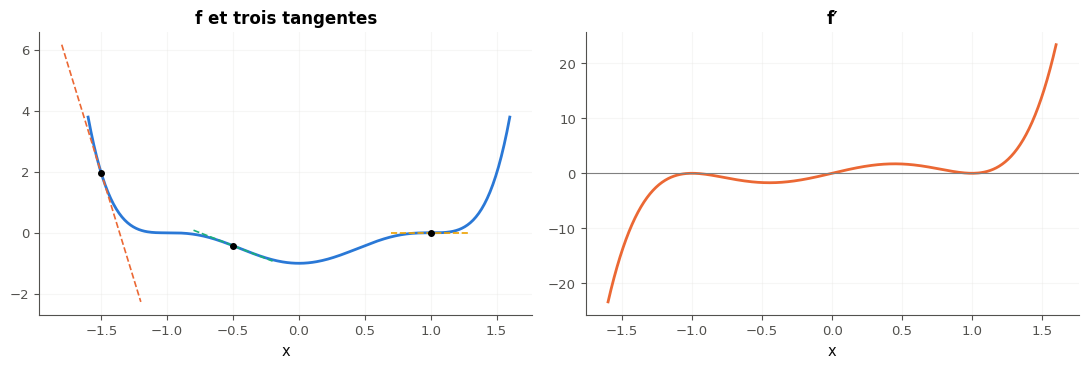

In [36]:
def plot_f_and_tangents(axes, f, df, points):
    """axes[0]: f on [-1.6, 1.6] and its tangent at each p of points (on [p − 0.3, p + 0.3]); axes[1]: df and y = 0."""
    xs = np.linspace(-1.6, 1.6, 300)
    axes[0].plot(xs, f(xs), linewidth=2, label="f")
    for p in points:
        segment = np.linspace(p - 0.3, p + 0.3, 2)
        axes[0].plot(segment, f(p) + df(p) * (segment - p), "--", linewidth=1.2)
        axes[0].plot([p], [f(p)], "o", color="black", markersize=4)
    axes[0].set_title("f et trois tangentes")
    axes[1].plot(xs, df(xs), linewidth=2, color="C1")
    axes[1].axhline(0, color="gray", linewidth=0.8)
    axes[1].set_title("f′")
    for ax in axes:
        ax.grid(True, alpha=0.3)
        ax.set_xlabel("x")


fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
plot_f_and_tangents(axes, f23, df23, points23)
fig.tight_layout()
plt.show()
answer_R7_23a = [-1, 0, 1]
answer_R7_23b = 1

In [37]:
wbm.record("R7.23a", [-1, 0, 1],
           mistakes={"f′(x) = 6x(x² − 1)² : chacun de ses facteurs peut s'annuler": [0],
                     "ce sont les zéros de f ; une tangente horizontale, c'est f′ qui s'annule": [-1, 1]})
wbm.record("R7.23b", 1, mistakes={"un point où f′ s'annule sans changer de signe n'est pas un extremum ; compte "
                                 "seulement ceux où f′ passe de − à +": {2, 3}})

WBM_ANSWER {"decimals": 0, "element_hashes": ["0c4dbb1aa54640fa14bcd518ea5186e868c2afa52726a339027605bb8113eb92", "dc529c4e801e34b133abb216af28f2434279b98745d710abb58e94350ba3013d", "d94c8f06556981bcaea689f1a66636013d14c5e1b7b0a2541ebc4a997d8441aa"], "hash": "783b9a0435e1cf4d58953225d1496caa485715b905acb4dc33550685aab44b79", "id": "R7.23a", "integer": true, "kind": "array", "mistakes": {"090b19b8dca1dc890e24fac20f6358d971ff64e3e1f4f55c6d4a181f3ddcfe2e": "f′(x) = 6x(x² − 1)² : chacun de ses facteurs peut s'annuler", "358a6e0721802dafbd6e0485a846a0a0d51884be3f04aa564364e94aa7fe8b36": "ce sont les zéros de f ; une tangente horizontale, c'est f′ qui s'annule"}, "shape": [3]}
📝 Ex R7.23a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"hash": "0cb6dd53d57987ee987c15b49313eb022dc1eae0ac22ee40204ec3306061d774", "id": "R7.23b", "kind": "int", "magnitude": 0, "mistakes": {"37ded1b09a179060fd73d4442b5f28f10272f6bed904c129bf3b1b3236baa8e9": "un point où f′ s'annule sans changer de signe n'

**Vérifications automatiques** (la figure elle-même se juge à l'œil).

In [38]:
with checked("R7.23 vérifications"):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    try:
        created = drawn(plot_f_and_tangents, axes, f23, df23, points23)
    finally:
        plt.close(fig)                                     # only the checks below are shown here
    problems = []
    if created:
        problems.append("ta fonction ouvre sa propre figure : dessine dans les axes reçus (axes[0].plot, …)")
    else:
        lines0 = [(np.asarray(l.get_xdata(), dtype=float), np.asarray(l.get_ydata(), dtype=float))
                  for l in axes[0].lines]
        lines1 = [(np.asarray(l.get_xdata(), dtype=float), np.asarray(l.get_ydata(), dtype=float))
                  for l in axes[1].lines]
        if not any(len(xs) >= 20 and np.allclose(ys, f23(xs)) for xs, ys in lines0):
            problems.append("la courbe de f n'est pas tracée dans axes[0] (au moins 20 points)")
        for p in points23:
            if not any(len(xs) >= 2 and np.allclose(ys, f23(p) + df23(p) * (xs - p)) and xs.min() < p < xs.max()
                       for xs, ys in lines0):
                problems.append(f"pas de tangente en {p} dans axes[0] : la droite y = f(p) + f′(p)(x − p), "
                                f"tracée avec plot de part et d'autre de p (pas axline)")
        if not any(len(xs) >= 20 and np.allclose(ys, df23(xs)) for xs, ys in lines1):
            problems.append("la courbe de f′ n'est pas tracée dans axes[1] (au moins 20 points)")
        if not any(len(ys) >= 2 and np.allclose(ys, 0) for xs, ys in lines1):
            problems.append("la droite y = 0 dans axes[1] (axes[1].axhline(0))")
        if not all(ax.get_title() for ax in axes):
            problems.append("un titre pour chaque graphique (ax.set_title)")
    if problems:
        print("❌ Ex R7.23 : à revoir : " + " ; ".join(problems) + ".")
    else:
        print("✅ Ex R7.23 : f, ses trois tangentes et f′, avec la droite y = 0.")

✅ Ex R7.23 : f, ses trois tangentes et f′, avec la droite y = 0.


💡 $f'(x) = 6x(x^2 - 1)^2$ s'annule en −1, 0 et 1, mais ne change de signe qu'en 0, car le facteur $(x^2 - 1)^2$ n'est jamais négatif : un seul minimum local, $f(0) = -1$. En −1 et en 1, la tangente est horizontale et la courbe la traverse : pas d'extremum, comme $x^5$ en 0 (fiche §8). Sur le graphique de droite, la courbe de $f'$ touche l'axe en ±1 sans le traverser.

## Partie C · Dérivées fausses et tests

Fiche §5 à §7. Quatre dérivées fausses à trouver, puis un test qui vérifie une dérivée.

### Ex R7.24 — Chasse à l'erreur : quatre dérivées fausses 🐛 ★★ ⏱️ 20 min
**Objectif :** repérer des dérivées fausses dans du code (règle du produit, règle de la chaîne), les corriger et les vérifier par un taux d'accroissement.  
**Prérequis :** fiche §6 et §7 · **Parcours :** C, E

Six fonctions Python calculent les dérivées de six fonctions (écrites en commentaire). Certaines lignes sont fausses. **Sans rien exécuter d'abord**, trouve-les.

```python
def d_a(x):  # derivative of x**2 * sqrt(x + 1)
    return 2 * x * (1 / (2 * math.sqrt(x + 1)))                   # (A)


def d_b(x):  # derivative of (x + 2) / (x - 3)
    return -5 / (x - 3) ** 2                                      # (B)


def d_c(x):  # derivative of exp(3 * x)
    return math.exp(3 * x)                                        # (C)


def d_d(x):  # derivative of ln(x**3 + 1)
    return 1 / (x ** 3 + 1)                                       # (D)


def d_e(x):  # derivative of sqrt(2 * x)
    return 1 / (2 * math.sqrt(2 * x))                             # (E)


def d_f(x):  # derivative of x**3 - 1 / x
    return 3 * x ** 2 + 1 / x ** 2                                # (F)
```

- a) les lettres des lignes fausses, dans l'ordre alphabétique (un texte) ;

Puis corrige-les dans la cellule ci-dessous (elle contient le code fautif). La fonction `slope(f, x)` de la cellule fournie calcule un taux d'accroissement avec $h = 10^{-6}$ : compare-le à chacune de tes dérivées en $x = 2$ pour les vérifier. La vérification calcule b), la liste des six valeurs `[d_a(2), d_b(2), …, d_f(2)]`.

Dans ta copie : pour chaque ligne fausse, quelle règle a été oubliée ? Laquelle des deux lignes justes pouvait sembler fausse, et pourquoi ne l'est-elle pas ?

In [39]:
def slope(f, x, h=1e-6):
    """A rate of change of f between x and x + h: close to f'(x) for a small h (fiche §3)."""
    return (f(x + h) - f(x)) / h

In [40]:
answer_R7_24a = "ACDE"

def d_a(x):  # derivative of x**2 * sqrt(x + 1)
    return 2 * x * math.sqrt(x + 1) + x ** 2 / (2 * math.sqrt(x + 1))   # (A) corrected: the product rule


def d_b(x):  # derivative of (x + 2) / (x - 3)
    return -5 / (x - 3) ** 2                                      # (B)


def d_c(x):  # derivative of exp(3 * x)
    return 3 * math.exp(3 * x)                                    # (C) corrected: times the derivative of 3x


def d_d(x):  # derivative of ln(x**3 + 1)
    return 3 * x ** 2 / (x ** 3 + 1)                              # (D) corrected: u'/u


def d_e(x):  # derivative of sqrt(2 * x)
    return 2 / (2 * math.sqrt(2 * x))                             # (E) corrected: times the derivative of 2x


def d_f(x):  # derivative of x**3 - 1 / x
    return 3 * x ** 2 + 1 / x ** 2                                # (F)


print(answer_R7_24a, [d_a(2), d_b(2), d_c(2), d_d(2), d_e(2), d_f(2)])
print("vérification par des taux :", [slope(lambda x: x ** 2 * math.sqrt(x + 1), 2), slope(lambda x: math.exp(3 * x), 2),
                                      slope(lambda x: math.log(x ** 3 + 1), 2), slope(lambda x: math.sqrt(2 * x), 2)])

ACDE [8.082903768654761, -5.0, 1210.2863804782053, 1.3333333333333333, 0.5, 12.25]
vérification par des taux : [8.082906560957781, 1210.2881960913692, 1.3333331110310098, 0.4999999374533104]


In [41]:
wbm.record("R7.24a", "ACDE",
           mistakes={"il manque une ligne fautive : x²√(x + 1) est un produit : sa dérivée n'est pas le produit des dérivées": "CDE",
                     "il manque une ligne fautive : e^(3x) est une composée : multiplie par la dérivée de l'étage intérieur": "ADE",
                     "il manque une ligne fautive : ln(x³ + 1) est une composée : (ln u)′ = u′/u": "ACE",
                     "il manque une ligne fautive : √(2x) est une composée : l'étage intérieur 2x a pour dérivée 2": "ACD",
                     "une ligne de trop : la ligne (B) est correcte ; relis ce qu'elle fait": "ABCDE",
                     "une ligne de trop : la ligne (F) est correcte ; relis ce qu'elle fait": "ACDEF",
                     "la ligne (B) est correcte, et il manque une ligne fautive : x²√(x + 1) est un produit : sa dérivée n'est pas le produit des dérivées": "BCDE",
                     "la ligne (F) est correcte, et il manque une ligne fautive : x²√(x + 1) est un produit : sa dérivée n'est pas le produit des dérivées": "CDEF",
                     "la ligne (B) est correcte, et il manque une ligne fautive : e^(3x) est une composée : multiplie par la dérivée de l'étage intérieur": "ABDE",
                     "la ligne (F) est correcte, et il manque une ligne fautive : e^(3x) est une composée : multiplie par la dérivée de l'étage intérieur": "ADEF",
                     "la ligne (B) est correcte, et il manque une ligne fautive : ln(x³ + 1) est une composée : (ln u)′ = u′/u": "ABCE",
                     "la ligne (F) est correcte, et il manque une ligne fautive : ln(x³ + 1) est une composée : (ln u)′ = u′/u": "ACEF",
                     "la ligne (B) est correcte, et il manque une ligne fautive : √(2x) est une composée : l'étage intérieur 2x a pour dérivée 2": "ABCD",
                     "la ligne (F) est correcte, et il manque une ligne fautive : √(2x) est une composée : l'étage intérieur 2x a pour dérivée 2": "ACDF",
                     "plusieurs lignes fautives manquent : reprends chaque ligne avec un petit exemple": {"A", "C", "D", "E", "AC", "AD", "AE", "CD", "CE", "DE"},
                     "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple": {"B", "F", "AB", "AF", "BC", "BD", "BE", "BF", "CF", "DF", "EF", "ABC", "ABD", "ABE", "ABF", "ACF", "ADF", "AEF", "BCD", "BCE", "BCF", "BDE", "BDF", "BEF", "CDF", "CEF", "DEF", "ABCF", "ABDF", "ABEF", "BCDF", "BCEF", "BDEF", "ABCDF", "ABCEF", "ABDEF", "BCDEF"},
                     "plusieurs lignes que tu cites sont correctes : vérifie chacune avec un petit exemple": {"ABCDEF"}})
wbm.record("R7.24b", [4 * math.sqrt(3) + 2 / math.sqrt(3), -5, 3 * math.exp(6), 4 / 3, 0.5, 12.25], decimals=4,
           mistakes={"aucune ligne n'est encore corrigée : corrige les lignes fausses dans la cellule où tu as écrit a)":
                         [2 / math.sqrt(3), -5, math.exp(6), 1 / 9, 1 / (2 * math.sqrt(4)), 12.25],
                     "d_a : la règle du produit donne deux termes": [4 * math.sqrt(3), -5, 3 * math.exp(6), 4 / 3, 0.5,
                                                                    12.25]})

WBM_ANSWER {"hash": "30eafdbd7b7841c598dbde6bf4e311e411ea08ff004b5ae04727c15c59e4d350", "id": "R7.24a", "kind": "str", "mistakes": {"0028c19a010dc171273b28387d449e75b3a8e837e883cff0e14053c5f3e1c7c3": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "0f8c2aab38e3d57556159fe88050b12836297d0acee006e9d951f38ec406e2f4": "la ligne (B) est correcte, et il manque une ligne fautive : x²√(x + 1) est un produit : sa dérivée n'est pas le produit des dérivées", "127c5ae4fa4f09d1228407510bed49c94a1409e5efaacba5cb87ef98851f6f19": "la ligne (B) est correcte, et il manque une ligne fautive : √(2x) est une composée : l'étage intérieur 2x a pour dérivée 2", "184533b87144e30d3ac77c2719ce9907c31a974004bdc296842e2754b436d35d": "la ligne (B) est correcte, et il manque une ligne fautive : ln(x³ + 1) est une composée : (ln u)′ = u′/u", "20d28a603e65fa792f8549c2d16e5b8dfac97ac9051bcbffc7148378a232f345": "il manque des lignes fautives, et d

💡 (A) $(x^2 \sqrt{x + 1})' = 2x\sqrt{x + 1} + \frac{x^2}{2\sqrt{x + 1}}$, la règle du produit. (C) $(e^{3x})' = 3e^{3x}$. (D) $(\ln(x^3 + 1))' = \frac{3x^2}{x^3 + 1}$. (E) $(\sqrt{2x})' = \frac{2}{2\sqrt{2x}} = \frac{1}{\sqrt{2x}}$. (B) est juste, malgré son signe moins : $\frac{1 \times (x - 3) - (x + 2) \times 1}{(x - 3)^2} = \frac{-5}{(x - 3)^2}$. (F) aussi : la dérivée de $-\frac{1}{x}$ est $+\frac{1}{x^2}$.

### Ex R7.25 — Tester une dérivée avec pytest et SymPy 🛠️ ★ ⏱️ 15 min
**Objectif :** écrire un test qui compare une dérivée calculée à la main à celle de SymPy, et vérifier qu'il sait dire non.  
**Prérequis :** fiche §5 et §6 ; R0 (pytest) · **Parcours :** C

Une dérivée calculée à la main se vérifie par un **test** : une fonction `test_...` que pytest exécute, et qui échoue si la dérivée est fausse. Ici :
1. Écris `dg(x)`, la dérivée de $g(x) = \frac{x^2 + 1}{x + 3}$, **calculée à la main** (règle du quotient, simplifiée) ;
2. Écris `test_dg_matches_sympy()`, **sans argument** : il crée son propre symbole (`X = sp.symbols("x")`, **dans** la fonction), calcule la dérivée de $g$ avec SymPy (`sp.diff`), puis vérifie avec `assert` et `math.isclose` que `dg` donne la même valeur qu'elle en au moins quatre points (pense à un point négatif ; évite −3). Pour évaluer une expression SymPy en un point : `float(expression.subs(X, point))`. Un message après l'`assert` (`assert ..., f"en {point} : {dg(point)}"`) dira où ça coince.

pytest exécute ta fonction de test **seule**, sans les autres cellules du notebook : tout ce qu'elle utilise (son symbole, l'expression de $g$) doit être défini dedans ; seuls `math`, `sp` et `dg` lui sont fournis.

La vérification lance ton test avec pytest (`wbm.run_pytest`) deux fois : sur ta `dg`, où il doit passer ; puis sur `dg_bug` (fournie), une dérivée fausse, où il doit **échouer**. Un test qui ne sait pas dire non ne vérifie rien.
- a) ton test passe-t-il sur `dg` ? ; b) échoue-t-il sur `dg_bug` ?

In [42]:
def dg_bug(x):
    """A wrong derivative of g(x) = (x**2 + 1) / (x + 3): u'v + uv' over v², with a + instead of a −."""
    return (2 * x * (x + 3) + (x ** 2 + 1)) / (x + 3) ** 2

In [43]:
def dg(x):
    """The derivative of g(x) = (x**2 + 1) / (x + 3), computed by hand (x != -3)."""
    return (x ** 2 + 6 * x - 1) / (x + 3) ** 2


def test_dg_matches_sympy():
    """dg agrees with the derivative of g computed by SymPy, at four points or more."""
    X = sp.symbols("x")
    exact = sp.diff((X ** 2 + 1) / (X + 3), X)
    for point in (-2.5, -1, 0, 0.5, 2, 10):
        assert math.isclose(dg(point), float(exact.subs(X, point)), rel_tol=1e-12, abs_tol=1e-12)


good = wbm.run_pytest(test_dg_matches_sympy, subject=dg, preamble="import sympy as sp", quiet=True)
bad = wbm.run_pytest(test_dg_matches_sympy, subject=dg_bug, name="dg", preamble="import sympy as sp", quiet=True)
print(f"sur dg : {good.summary} ; sur dg_bug : {bad.summary}")

sur dg : 1 passed in 0.25s ; sur dg_bug : 1 failed in 0.31s


In [44]:
wbm.record("R7.25a", True,
           mistakes={"ton test échoue sur ta propre dg : relis ta dérivée (u′v − uv′ sur v²) ou ton test (lis la sortie "
                     "de pytest : print(good.output))": False})
wbm.record("R7.25b", True,
           mistakes={"ton test ne voit pas l'erreur de dg_bug (ou il échoue pour une autre raison qu'un assert) : "
                     "compare en plusieurs points, avec une tolérance serrée (math.isclose)": False})

WBM_ANSWER {"hash": "235b2bfb99ca0473995157abfa00a042353a27865709524185317f080a9a7ac8", "id": "R7.25a", "kind": "bool", "mistakes": {"487336a30d78c6c2145e8856dd3b0c84e7a7f1e061a94bfd4bfbc926f7a445ea": "ton test échoue sur ta propre dg : relis ta dérivée (u′v − uv′ sur v²) ou ton test (lis la sortie de pytest : print(good.output))"}}
📝 Ex R7.25a : réponse enregistrée (bool).
WBM_ANSWER {"hash": "d2046ec84bb09a5e96dbc86a8446fb6d349205ca13a087c194dd0cc630467a31", "id": "R7.25b", "kind": "bool", "mistakes": {"7bc901e777d53840e8e0febd67328048ccce828acf56d22493a1264bcc14211e": "ton test ne voit pas l'erreur de dg_bug (ou il échoue pour une autre raison qu'un assert) : compare en plusieurs points, avec une tolérance serrée (math.isclose)"}}
📝 Ex R7.25b : réponse enregistrée (bool).


💡 $g'(x) = \frac{2x(x + 3) - (x^2 + 1)}{(x + 3)^2} = \frac{x^2 + 6x - 1}{(x + 3)^2}$. Un test qui compare en un seul point peut tomber sur un point où une dérivée fausse est juste par hasard ; plusieurs points, dont un négatif, rendent ce hasard très improbable.

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Calcules-tu une limite en l'infini ou en un point, et repères-tu une asymptote ?
2. Dérives-tu sans hésiter un produit, un quotient et une composée, et écris-tu une tangente ?
3. Sais-tu étudier les variations d'une fonction et trouver son minimum, y compris aux bords ?

**La suite** : R8, *Probabilités de base*. Dans workbookIA, continue le chapitre 0A au rythme de ton tableau de bord.